### Group 6
## Project: Buisness Requirement Management

#### Business Objective:
To minimize inventory-related operational costs and lost sales opportunities by accurately predicting whether a product is at risk of stockout or overstock. This prediction enables proactive decision-making in procurement, demand planning, and supply chain management, thereby optimizing service levels and reducing holding and shortage costs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder

df = pd.read_excel('stock_risk_prediction_dataset (1).xlsx')
print("Shape:", df.shape)
df.head(10)

Shape: (5000, 11)


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
0,549,45.76,5.64,342.83,1604.49,4.17,-9.90,peak,essential,low,overstock
1,486,45.47,6.39,348.37,1585.00,4.01,-5.27,peak,non-essential,high,overstock
2,564,32.04,5.81,353.21,1219.04,3.57,-2.94,off-peak,non-essential,high,overstock
3,652,46.70,7.22,397.34,1673.88,4.00,0.75,off-peak,essential,low,overstock
4,476,57.33,9.39,312.64,1052.98,4.49,5.12,peak,essential,high,overstock
5,476,37.26,5.46,307.68,1303.74,3.87,3.47,peak,essential,high,overstock
6,657,60.48,9.00,411.83,900.27,4.42,-5.90,peak,non-essential,low,overstock
7,576,54.88,5.44,326.87,1967.59,3.16,-1.86,off-peak,non-essential,low,overstock
8,453,42.66,5.30,286.85,1430.54,3.40,0.38,off-peak,essential,low,overstock
9,554,48.58,8.64,325.74,2150.07,3.27,-1.31,off-peak,non-essential,high,overstock


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5000
Number of columns: 11


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   current_stock         5000 non-null   int64  
 1   avg_daily_demand      5000 non-null   float64
 2   lead_time_days        5000 non-null   float64
 3   reorder_point         5000 non-null   float64
 4   sales_last_30_days    5000 non-null   float64
 5   stock_turnover_ratio  5000 non-null   float64
 6   forecast_error        5000 non-null   float64
 7   season                5000 non-null   str    
 8   item_category         5000 non-null   str    
 9   supplier_reliability  5000 non-null   str    
 10  stock_status          5000 non-null   str    
dtypes: float64(6), int64(1), str(4)
memory usage: 573.4 KB


In [4]:
print("Column Names:")
for column in df.columns:
    print(column)

Column Names:
current_stock
avg_daily_demand
lead_time_days
reorder_point
sales_last_30_days
stock_turnover_ratio
forecast_error
season
item_category
supplier_reliability
stock_status


In [5]:
print("Data Types:")
print(df.dtypes)

Data Types:
current_stock             int64
avg_daily_demand        float64
lead_time_days          float64
reorder_point           float64
sales_last_30_days      float64
stock_turnover_ratio    float64
forecast_error          float64
season                      str
item_category               str
supplier_reliability        str
stock_status                str
dtype: object


In [6]:
print("Number of Unique Values in Each Column:")
print(df.nunique())

Number of Unique Values in Each Column:
current_stock            529
avg_daily_demand        2794
lead_time_days           945
reorder_point           4357
sales_last_30_days      4875
stock_turnover_ratio     529
forecast_error          1882
season                     2
item_category              2
supplier_reliability       2
stock_status               2
dtype: int64


In [7]:
categorical_columns = [
    'season',
    'item_category',
    'supplier_reliability',
    'stock_status']

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


season:
<ArrowStringArray>
['peak', 'off-peak']
Length: 2, dtype: str

item_category:
<ArrowStringArray>
['essential', 'non-essential']
Length: 2, dtype: str

supplier_reliability:
<ArrowStringArray>
['low', 'high']
Length: 2, dtype: str

stock_status:
<ArrowStringArray>
['overstock', 'stockout']
Length: 2, dtype: str


In [8]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
current_stock           0
avg_daily_demand        0
lead_time_days          0
reorder_point           0
sales_last_30_days      0
stock_turnover_ratio    0
forecast_error          0
season                  0
item_category           0
supplier_reliability    0
stock_status            0
dtype: int64


In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [10]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [11]:

print("Stock Status Distribution:")
print(df['stock_status'].value_counts())

print("\nStock Status Percentage:")
print(df['stock_status'].value_counts(normalize=True) * 100)

Stock Status Distribution:
stock_status
overstock    4543
stockout      457
Name: count, dtype: int64

Stock Status Percentage:
stock_status
overstock    90.86
stockout      9.14
Name: proportion, dtype: float64


In [12]:
data_audit = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values,
    'Missing Values': df.isnull().sum().values,
    'Unique Values': df.nunique().values
})

data_audit

,Column,Data Type,Missing Values,Unique Values
0,current_stock,int64,0,529
1,avg_daily_demand,float64,0,2794
2,lead_time_days,float64,0,945
3,reorder_point,float64,0,4357
4,sales_last_30_days,float64,0,4875
5,stock_turnover_ratio,float64,0,529
6,forecast_error,float64,0,1882
7,season,str,0,2
8,item_category,str,0,2
9,supplier_reliability,str,0,2


## Data Quality Report:
- The Stock Risk Prediction Dataset contains 5,000 records and 11 columns. The dataset consists of 7 numerical variables and 4 categorical variables.
- All columns contain valid data types according to their nature. There are no missing values and no duplicate records in the dataset. The categorical variables contain two distinct categories each, with no unexpected values identified.
- The target variable, stock_status, contains two classes: overstock and stockout.
- The target distribution is imbalanced, with 90.86% of records classified as overstock and 9.14% as stockout. This class imbalance should be considered during subsequent model development and evaluation.

## Univariate EDA – Numerical Variables

In [13]:
numerical_columns = [
    'current_stock',
    'avg_daily_demand',
    'lead_time_days',
    'reorder_point',
    'sales_last_30_days',
    'stock_turnover_ratio',
    'forecast_error'
]

print("Numerical Variables:")
for column in numerical_columns:
    print(column)

Numerical Variables:
current_stock
avg_daily_demand
lead_time_days
reorder_point
sales_last_30_days
stock_turnover_ratio
forecast_error


In [14]:
numerical_summary = df[numerical_columns].describe()

numerical_summary

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,500.065800,49.901224,7.021084,350.825734,1494.494344,3.993402,-0.054578
std,99.647785,10.104358,1.997617,50.166808,295.012442,0.999404,5.129634
min,175.000000,10.780000,0.250000,157.180000,403.470000,0.550000,-22.330000
25%,434.000000,43.130000,5.680000,316.765000,1289.470000,3.300000,-3.540000
50%,501.000000,49.825000,7.020000,350.960000,1497.595000,4.000000,-0.120000
75%,566.000000,56.772500,8.350000,385.332500,1695.180000,4.680000,3.442500
max,892.000000,85.290000,13.860000,573.950000,2583.410000,7.690000,18.640000


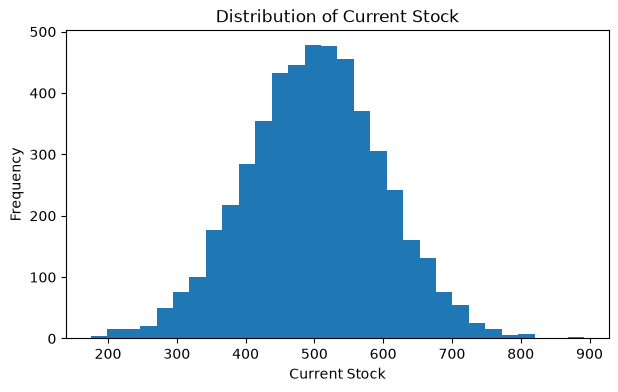

In [15]:
plt.figure(figsize=(7, 4))

plt.hist(df['current_stock'], bins=30)

plt.xlabel('Current Stock')
plt.ylabel('Frequency')
plt.title('Distribution of Current Stock')

plt.show()

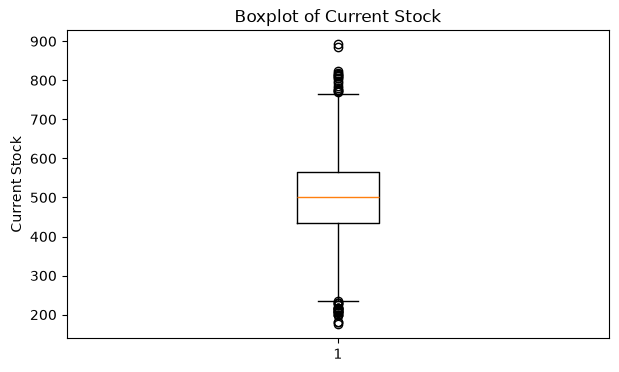

In [16]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['current_stock'])

plt.ylabel('Current Stock')
plt.title('Boxplot of Current Stock')

plt.show()

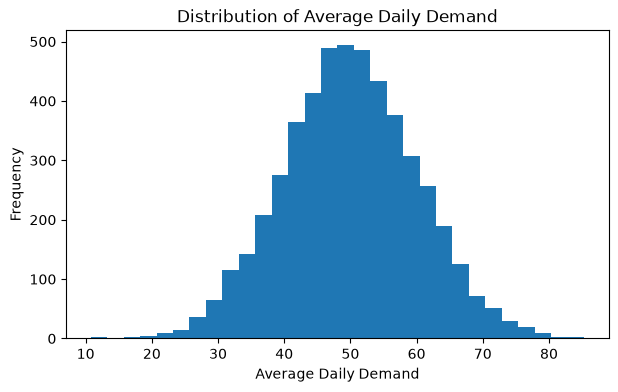

In [17]:
plt.figure(figsize=(7, 4))

plt.hist(df['avg_daily_demand'], bins=30)

plt.xlabel('Average Daily Demand')
plt.ylabel('Frequency')
plt.title('Distribution of Average Daily Demand')

plt.show()

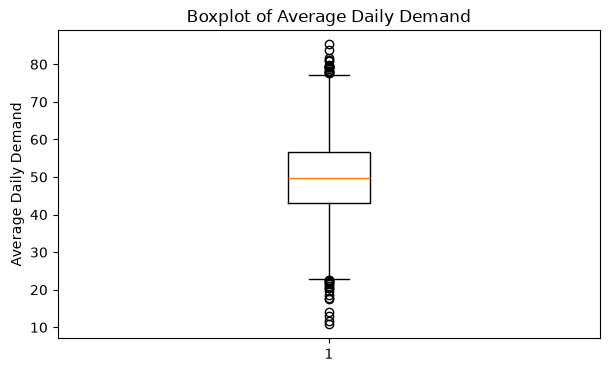

In [18]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['avg_daily_demand'])

plt.ylabel('Average Daily Demand')
plt.title('Boxplot of Average Daily Demand')

plt.show()

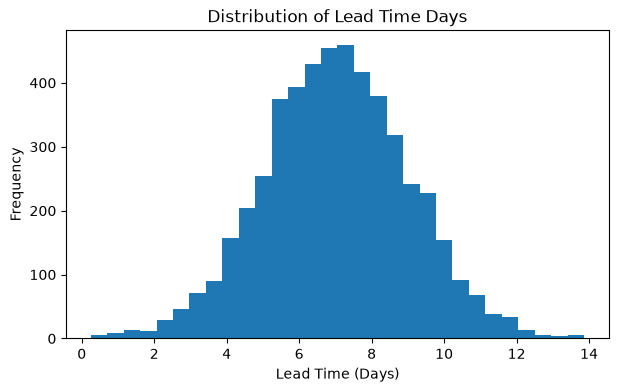

In [19]:
plt.figure(figsize=(7, 4))

plt.hist(df['lead_time_days'], bins=30)

plt.xlabel('Lead Time (Days)')
plt.ylabel('Frequency')
plt.title('Distribution of Lead Time Days')

plt.show()

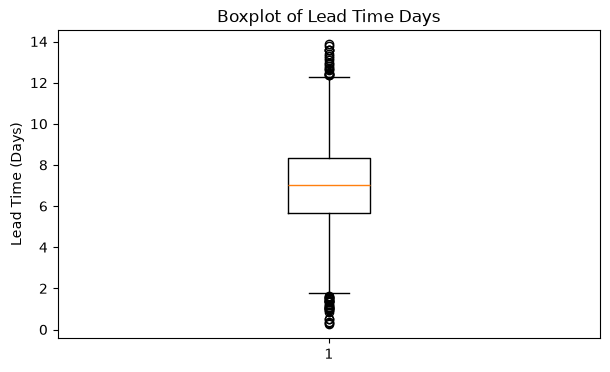

In [20]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['lead_time_days'])

plt.ylabel('Lead Time (Days)')
plt.title('Boxplot of Lead Time Days')

plt.show()

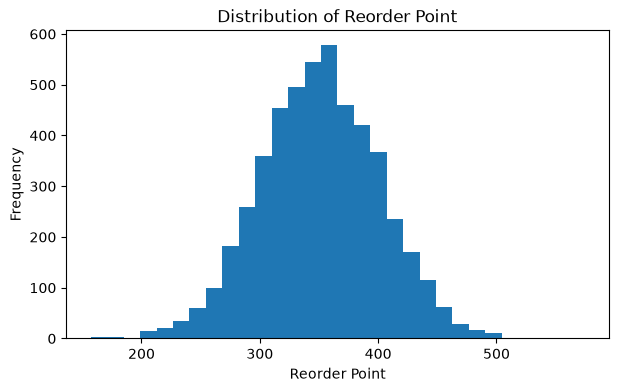

In [21]:
plt.figure(figsize=(7, 4))

plt.hist(df['reorder_point'], bins=30)

plt.xlabel('Reorder Point')
plt.ylabel('Frequency')
plt.title('Distribution of Reorder Point')

plt.show()

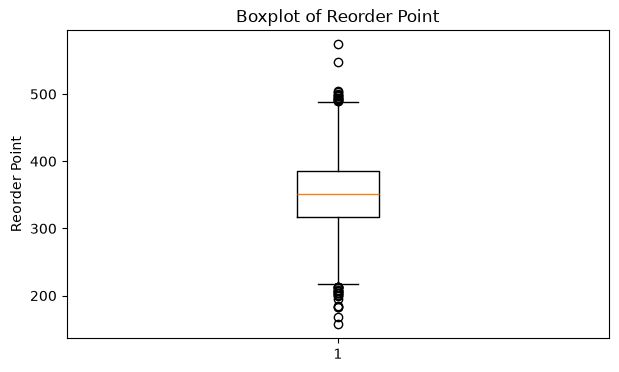

In [22]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['reorder_point'])

plt.ylabel('Reorder Point')
plt.title('Boxplot of Reorder Point')

plt.show()

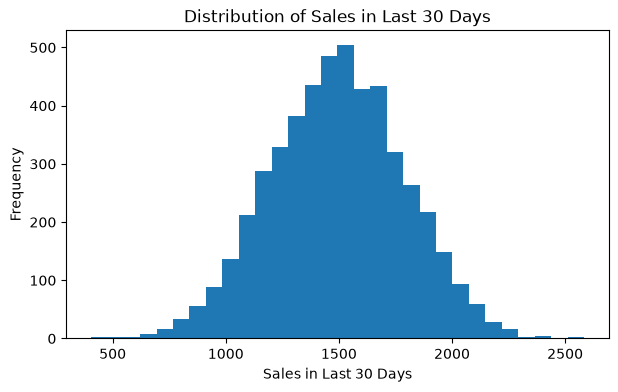

In [23]:
plt.figure(figsize=(7, 4))

plt.hist(df['sales_last_30_days'], bins=30)

plt.xlabel('Sales in Last 30 Days')
plt.ylabel('Frequency')
plt.title('Distribution of Sales in Last 30 Days')

plt.show()

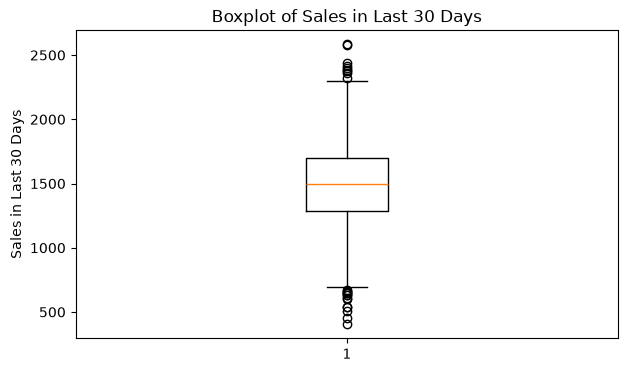

In [24]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['sales_last_30_days'])

plt.ylabel('Sales in Last 30 Days')
plt.title('Boxplot of Sales in Last 30 Days')

plt.show()

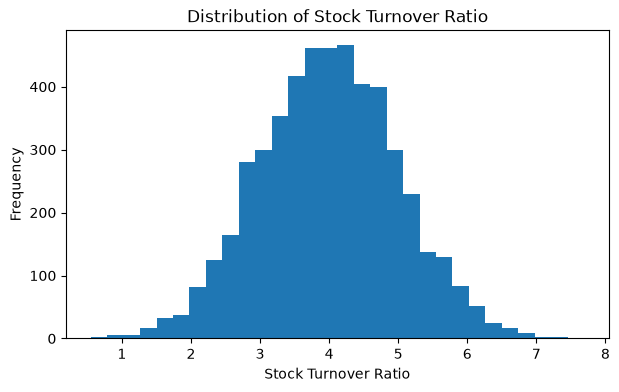

In [25]:
plt.figure(figsize=(7, 4))

plt.hist(df['stock_turnover_ratio'], bins=30)

plt.xlabel('Stock Turnover Ratio')
plt.ylabel('Frequency')
plt.title('Distribution of Stock Turnover Ratio')

plt.show()

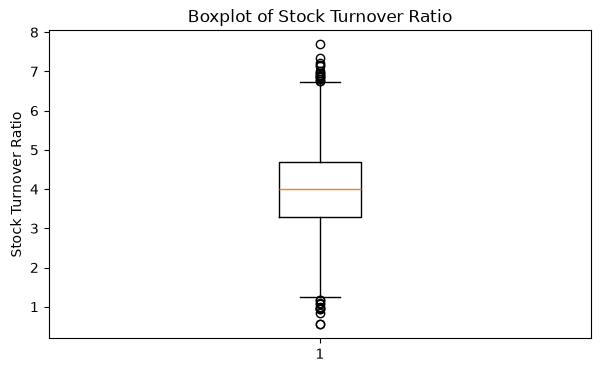

In [26]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['stock_turnover_ratio'])

plt.ylabel('Stock Turnover Ratio')
plt.title('Boxplot of Stock Turnover Ratio')

plt.show()

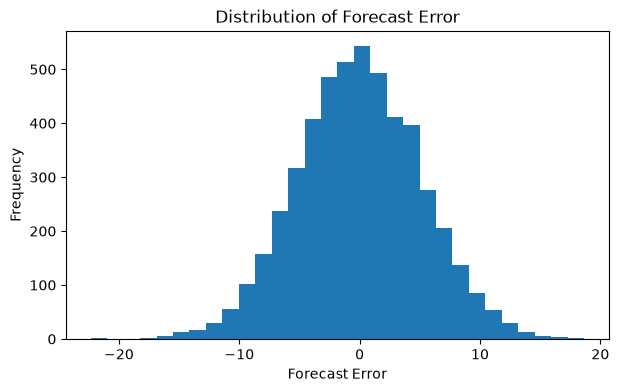

In [27]:
plt.figure(figsize=(7, 4))

plt.hist(df['forecast_error'], bins=30)

plt.xlabel('Forecast Error')
plt.ylabel('Frequency')
plt.title('Distribution of Forecast Error')

plt.show()

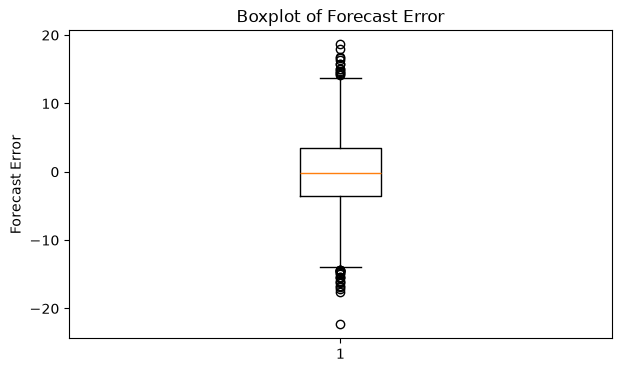

In [28]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['forecast_error'])

plt.ylabel('Forecast Error')
plt.title('Boxplot of Forecast Error')

plt.show()

##  Numerical EDA Observations

- **Current Stock:** Most values are between 400 and 600 units, with a median of around 500 units. The distribution is slightly right-skewed.

- **Average Daily Demand:** Most values are between 40 and 60 units/day, with a median of around 50 units/day. The distribution is roughly symmetric.

- **Lead Time Days:** Most values are between 5 and 9 days, with a median of around 7 days. The distribution is roughly symmetric.

- **Reorder Point:** Most values are between 300 and 400 units, with a median of around 350 units. The distribution is roughly symmetric.

- **Sales Last 30 Days:** Most values are between 1,200 and 1,800 units, with a median of around 1,500 units. The distribution is roughly symmetric.

- **Stock Turnover Ratio:** Most values are between 3 and 5, with a median of around 4. The distribution is slightly right-skewed.

- **Forecast Error:** The values are mainly concentrated around 0, with most observations between approximately -5 and 5. The distribution is roughly symmetric around zero.

- The boxplots for the numerical variables show some values that are far from the main range of the data.

## Univariate EDA – Categorical Variables

In [29]:
print("Season:", df["season"].unique())
print("Item Category:", df["item_category"].unique())
print("Supplier Reliability:", df["supplier_reliability"].unique())

Season: <ArrowStringArray>
['peak', 'off-peak']
Length: 2, dtype: str
Item Category: <ArrowStringArray>
['essential', 'non-essential']
Length: 2, dtype: str
Supplier Reliability: <ArrowStringArray>
['low', 'high']
Length: 2, dtype: str


In [30]:
print("Season")
print(df["season"].value_counts())

print("\nItem Category")
print(df["item_category"].value_counts())

print("\nSupplier Reliability")
print(df["supplier_reliability"].value_counts())

Season
season
off-peak    2508
peak        2492
Name: count, dtype: int64

Item Category
item_category
essential        2505
non-essential    2495
Name: count, dtype: int64

Supplier Reliability
supplier_reliability
low     2514
high    2486
Name: count, dtype: int64


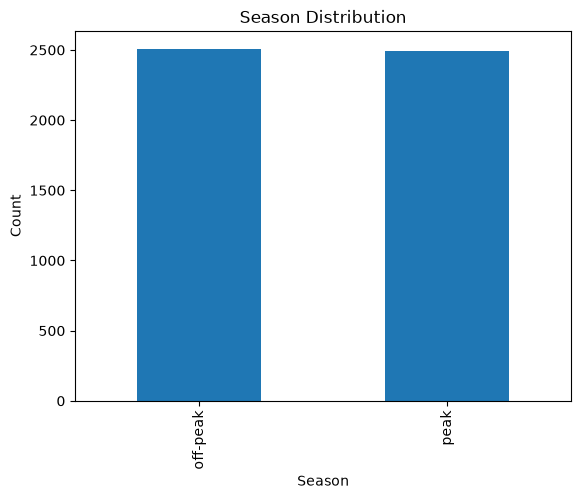

In [31]:
df["season"].value_counts().plot(kind="bar")

plt.title("Season Distribution")
plt.xlabel("Season")
plt.ylabel("Count")
plt.show()

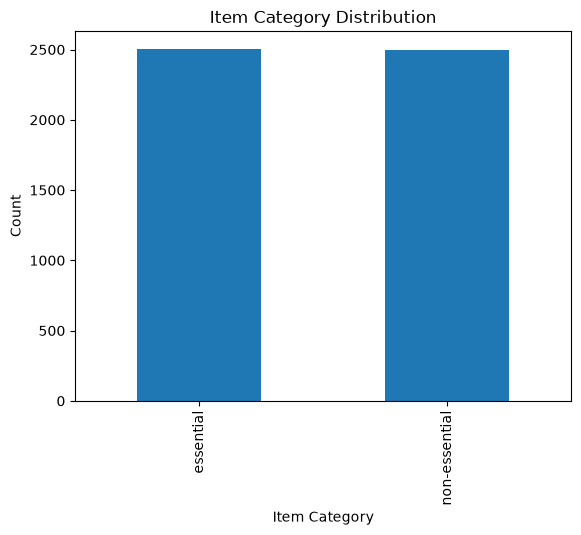

In [32]:
df["item_category"].value_counts().plot(kind="bar")

plt.title("Item Category Distribution")
plt.xlabel("Item Category")
plt.ylabel("Count")
plt.show()

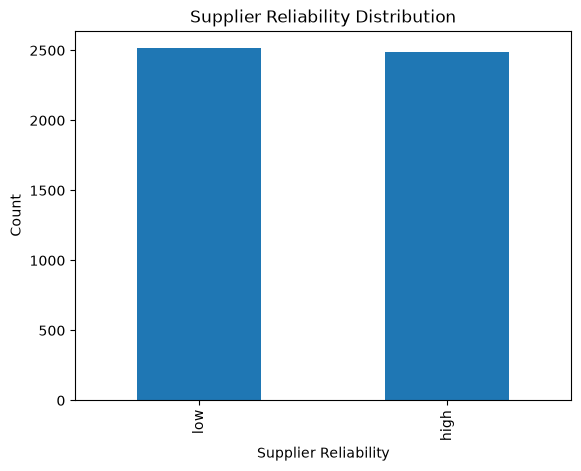

In [33]:
df["supplier_reliability"].value_counts().plot(kind="bar")

plt.title("Supplier Reliability Distribution")
plt.xlabel("Supplier Reliability")
plt.ylabel("Count")
plt.show()

In [34]:
print(df["season"].value_counts(normalize=True) * 100)

print(df["item_category"].value_counts(normalize=True) * 100)

print(df["supplier_reliability"].value_counts(normalize=True) * 100)

season
off-peak    50.16
peak        49.84
Name: proportion, dtype: float64
item_category
essential        50.1
non-essential    49.9
Name: proportion, dtype: float64
supplier_reliability
low     50.28
high    49.72
Name: proportion, dtype: float64


The categorical variables analyzed in the dataset are season, item_category, and supplier_reliability.

Each variable contains two categories. Frequency counts, unique values, bar charts, and percentage distributions were used to understand the categorical data.

The season variable contains 2508 off-peak records and 2492 peak records. The item_category variable contains 2505 essential and 2495 non-essential records. The supplier_reliability variable contains 2514 low reliability and 2486 high reliability records.

The category percentages are very close to 50% for all three variables. Therefore, no significant category imbalance is observed in the categorical features.

These categorical variables can be considered well distributed and can be used in further stages of the project.

# Target Variable & Bivariate EDA

**Target classes:** `overstock` and `stockout`

In [35]:
# Confirm target values and create a binary target for correlation analysis
target = 'stock_status'

print("Target variable:", target)
print("Target values:", df[target].unique())

target_counts = df[target].value_counts()
target_pct = df[target].value_counts(normalize=True).mul(100).round(2)

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_pct
})
target_summary


Target variable: stock_status
Target values: <ArrowStringArray>
['overstock', 'stockout']
Length: 2, dtype: str


,Count,Percentage
stock_status,,
overstock,4543,90.86
stockout,457,9.14


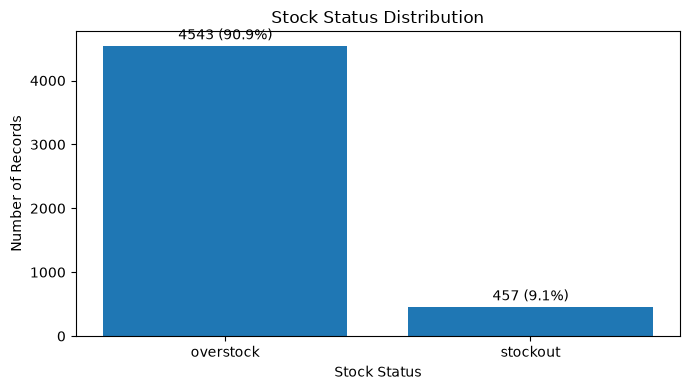

In [36]:
# Target distribution plot
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
bars = plt.bar(target_summary.index, target_summary['Count'])
plt.title('Stock Status Distribution')
plt.xlabel('Stock Status')
plt.ylabel('Number of Records')

for bar, value in zip(bars, target_summary['Count']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f'{value} ({value/len(df)*100:.1f}%)',
             ha='center', va='bottom')

plt.tight_layout()
plt.show()


### Target distribution — observation
- **Overstock:** 4,543 records (**90.86%**)
- **Stockout:** 457 records (**9.14%**)
- The target is **strongly imbalanced**.
- Therefore, a predictive model should not rely on accuracy alone; metrics such as **precision, recall, F1-score and ROC-AUC/PR-AUC** should also be considered.


In [37]:
# Compare all numerical features by stock status
numeric_features = df.select_dtypes(include=np.number).columns.tolist()

numeric_summary = df.groupby(target)[numeric_features].agg(['mean', 'median'])
numeric_summary.round(2)


current_stock        avg_daily_demand        lead_time_days  \
                      mean median             mean median           mean   
stock_status                                                               
overstock           516.32  514.0            49.89  49.82           7.03   
stockout            338.51  344.0            50.01  50.02           6.96   

                    reorder_point        sales_last_30_days           \
             median          mean median               mean   median   
stock_status                                                           
overstock      7.03        346.65  346.7            1495.41  1496.10   
stockout       6.88        392.34  392.6            1485.37  1504.61   

             stock_turnover_ratio        forecast_error         
                             mean median           mean median  
stock_status                                                    
overstock                    3.99   3.98          -0.04  -0.12  
stockout                     4.07   4.11          -0.25  -0.23

In [38]:
# Stockout rate correlation with numerical features
binary_target = (df[target] == 'stockout').astype(int)

numeric_corr = (
    df[numeric_features]
    .corrwith(binary_target)
    .sort_values()
    .to_frame('Correlation_with_stockout')
)

numeric_corr.round(3)


,Correlation_with_stockout
current_stock,-0.514
forecast_error,-0.012
lead_time_days,-0.010
sales_last_30_days,-0.010
avg_daily_demand,0.004
stock_turnover_ratio,0.025
reorder_point,0.262


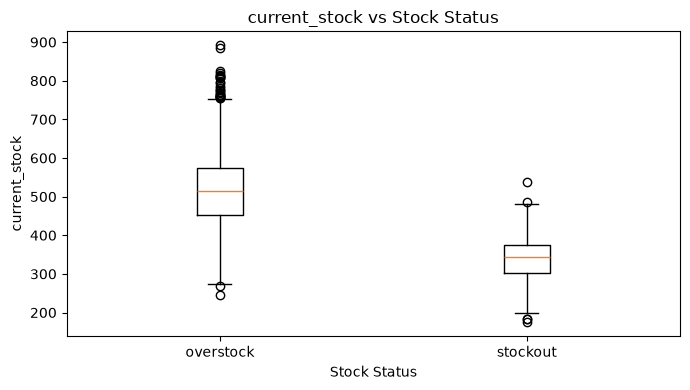

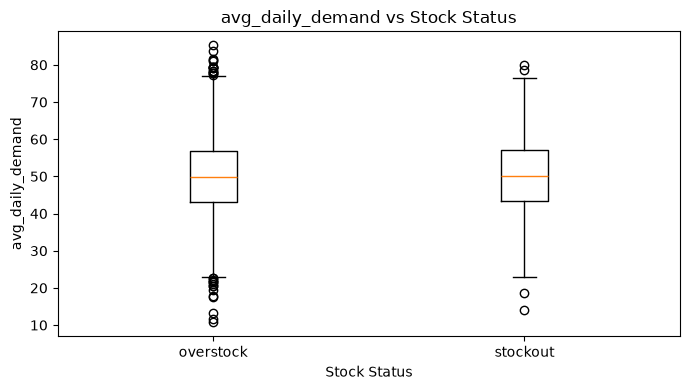

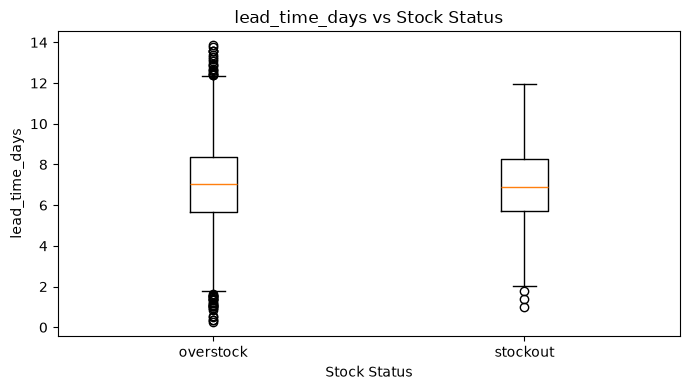

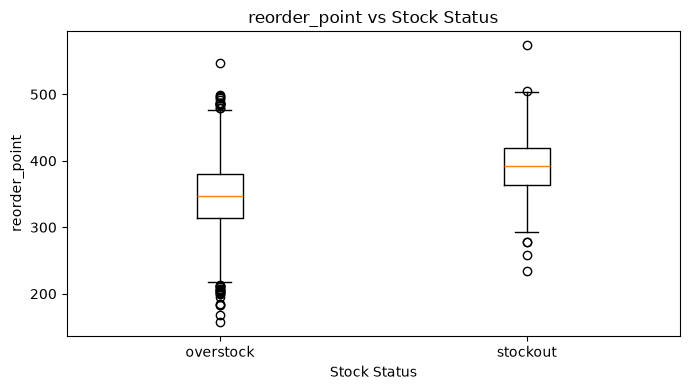

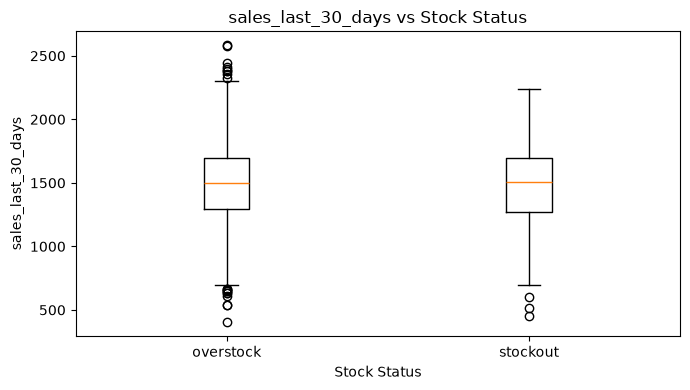

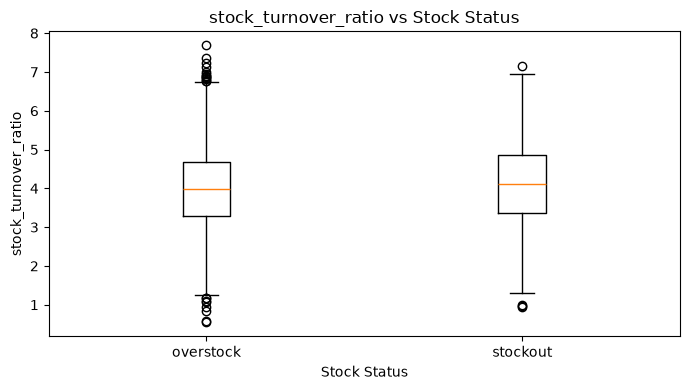

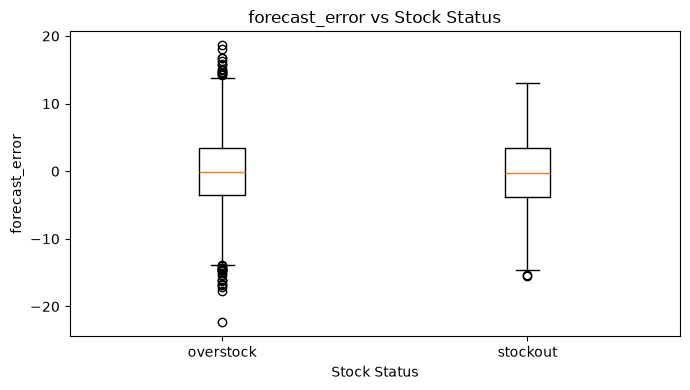

In [39]:
# Boxplots: numerical features against stock status
for feature in numeric_features:
    groups = [
        df.loc[df[target] == 'overstock',
            feature],
        df.loc[df[target] == 'stockout',
            feature]
    ]
    plt.figure(figsize=(7, 4))
    plt.boxplot(
        groups,
        tick_labels=['overstock', 'stockout'])
    plt.title(f'{feature} vs Stock Status')
    plt.xlabel('Stock Status')
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

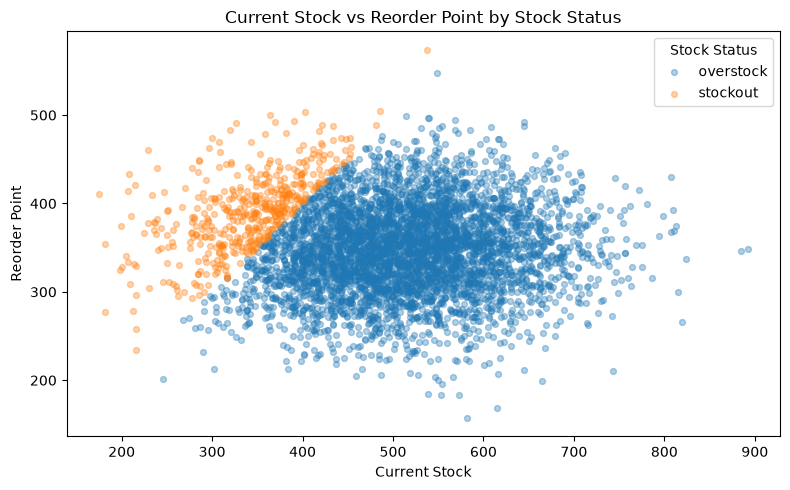

In [40]:
# Most important numerical relationships: current stock vs reorder point
plt.figure(figsize=(8, 5))

for status in ['overstock', 'stockout']:
    subset = df[df[target] == status]
    plt.scatter(
        subset['current_stock'],
        subset['reorder_point'],
        alpha=0.35,
        s=18,
        label=status
    )

plt.title('Current Stock vs Reorder Point by Stock Status')
plt.xlabel('Current Stock')
plt.ylabel('Reorder Point')
plt.legend(title='Stock Status')
plt.tight_layout()
plt.show()


In [41]:
# Categorical features: counts and stockout rate
categorical_features = ['season', 'item_category', 'supplier_reliability']

categorical_results = []

for feature in categorical_features:
    rate = df.groupby(feature)[target].apply(lambda s: (s == 'stockout').mean() * 100)
    counts = df.groupby([feature, target]).size().unstack(fill_value=0)

    print(f"\n{feature.upper()}")
    print("Counts:")
    display(counts)
    print("Stockout rate (%):")
    display(rate.round(2).to_frame('Stockout_Rate_%'))

    categorical_results.append(
        rate.rename(feature)
    )



SEASON
Counts:


stock_status,overstock,stockout
season,,
off-peak,2278,230
peak,2265,227


Stockout rate (%):


,Stockout_Rate_%
season,
off-peak,9.17
peak,9.11



ITEM_CATEGORY
Counts:


...

,Stockout_Rate_%
item_category,
essential,9.02
non-essential,9.26



SUPPLIER_RELIABILITY
Counts:


stock_status,overstock,stockout
supplier_reliability,,
high,2253,233
low,2290,224


Stockout rate (%):


,Stockout_Rate_%
supplier_reliability,
high,9.37
low,8.91


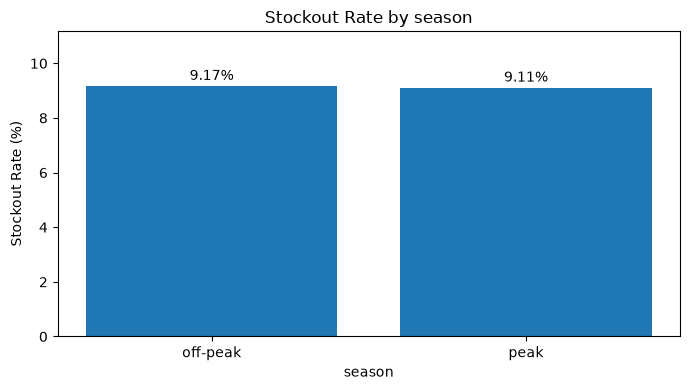

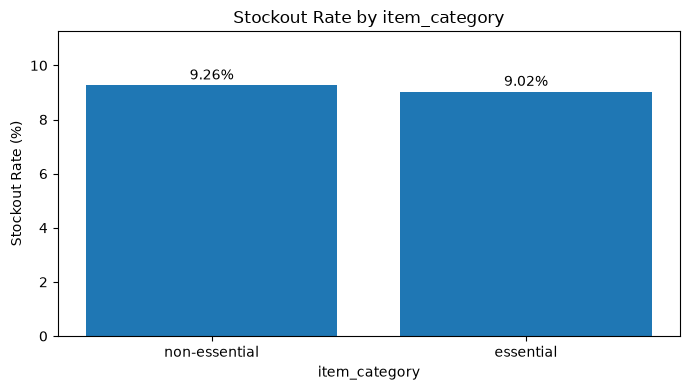

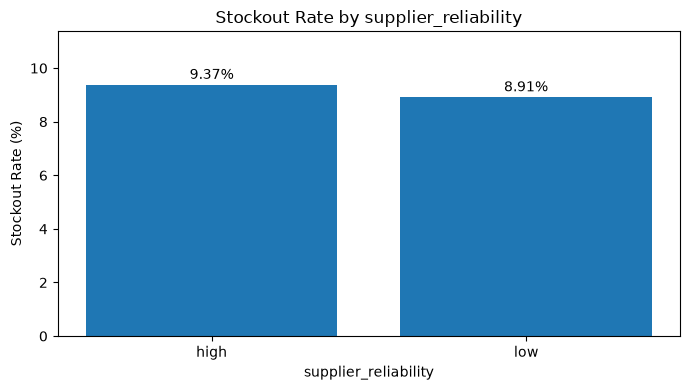

In [42]:
# Plot stockout rate for each categorical feature
for feature in categorical_features:
    stockout_rate = (
        df.groupby(feature)[target]
        .apply(lambda s: (s == 'stockout').mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(7, 4))
    bars = plt.bar(stockout_rate.index.astype(str), stockout_rate.values)
    plt.title(f'Stockout Rate by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Stockout Rate (%)')

    for bar, value in zip(bars, stockout_rate.values):
        plt.text(bar.get_x() + bar.get_width()/2, value + 0.1,
                 f'{value:.2f}%', ha='center', va='bottom')

    plt.ylim(0, max(stockout_rate.values) + 2)
    plt.tight_layout()
    plt.show()


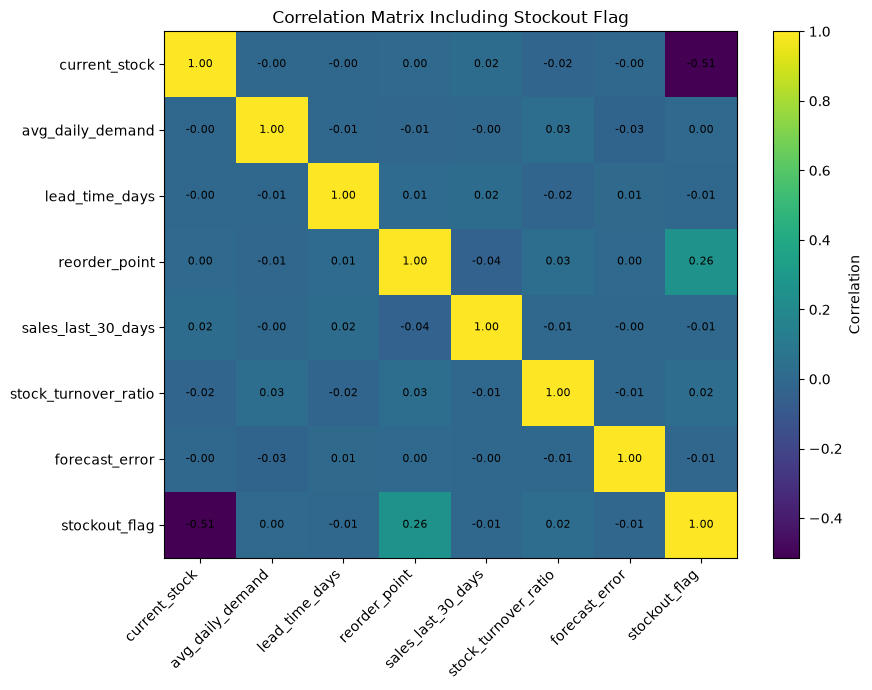

In [43]:
# Target relationship heatmap using correlations
corr_data = df[numeric_features].copy()
corr_data['stockout_flag'] = binary_target

corr = corr_data.corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, aspect='auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.index)), corr.index)
plt.title('Correlation Matrix Including Stockout Flag')

# Add correlation values
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}',
                 ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.show()


In [44]:
# Create a concise relationship table for the report
relationship_table = pd.DataFrame({
    'Feature': numeric_features,
    'Overstock_Mean': [df.loc[df[target]=='overstock', c].mean() for c in numeric_features],
    'Stockout_Mean': [df.loc[df[target]=='stockout', c].mean() for c in numeric_features],
    'Correlation_with_Stockout': [df[c].corr(binary_target) for c in numeric_features]
})

relationship_table['Absolute_Correlation'] = relationship_table['Correlation_with_Stockout'].abs()
relationship_table = relationship_table.sort_values('Absolute_Correlation', ascending=False)

relationship_table.round(3)


,Feature,Overstock_Mean,Stockout_Mean,Correlation_with_Stockout,Absolute_Correlation
0,current_stock,516.317,338.510,-0.514,0.514
3,reorder_point,346.650,392.335,0.262,0.262
5,stock_turnover_ratio,3.986,4.072,0.025,0.025
6,forecast_error,-0.035,-0.249,-0.012,0.012
2,lead_time_days,7.027,6.959,-0.010,0.010
4,sales_last_30_days,1495.412,1485.368,-0.010,0.010
1,avg_daily_demand,49.890,50.014,0.004,0.004


## Key Bivariate EDA Findings

### Numerical features
1. **`current_stock` is the strongest numerical indicator of `stock_status`**. Its correlation with the stockout flag is about **-0.514**, meaning lower current stock is strongly associated with stockout.
2. **`reorder_point`** has the second-strongest relationship, with correlation about **+0.262** with stockout. Stockout records have a higher average reorder point (**~392.34**) than overstock records (**~346.65**).
3. The other numerical variables show comparatively weak direct relationships with the target:
   - `stock_turnover_ratio`: very weak positive relationship
   - `avg_daily_demand`: almost no linear relationship
   - `lead_time_days`: almost no linear relationship
   - `sales_last_30_days`: almost no linear relationship
   - `forecast_error`: almost no linear relationship
4. The **current-stock vs reorder-point scatter plot** is particularly useful because stockout cases tend to occur at lower current-stock levels relative to the reorder point.

### Categorical features
1. **Season:** stockout rates are almost identical for peak and off-peak periods (~9.1%).
2. **Item category:** essential and non-essential items also have very similar stockout rates (~9.0–9.3%).
3. **Supplier reliability:** high- and low-reliability suppliers show only a small difference in stockout rate (~9.4% vs ~8.9%).

### Business conclusion
The EDA suggests that **inventory position variables, especially current stock and reorder point, are more informative for stock-risk prediction than the categorical variables examined here**. The strong class imbalance should also be handled carefully during model training and evaluation.


In [45]:
#Check missing value
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
current_stock           0
avg_daily_demand        0
lead_time_days          0
reorder_point           0
sales_last_30_days      0
stock_turnover_ratio    0
forecast_error          0
season                  0
item_category           0
supplier_reliability    0
stock_status            0
dtype: int64


In [46]:
#Handle missing values
numerical_columns = df.select_dtypes(include=["int64",
                                              "float64"]).columns
categorical_columns = df.select_dtypes(include=["object",
                                               "string"]).columns



#Fill numerical missing values with median
for column in numerical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())


#Fill categorical missing values with median
for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())



Missing values after cleaning:
current_stock           0
avg_daily_demand        0
lead_time_days          0
reorder_point           0
sales_last_30_days      0
stock_turnover_ratio    0
forecast_error          0
season                  0
item_category           0
supplier_reliability    0
stock_status            0
dtype: int64


In [47]:
#Handle duplicates
print("Duplicated rows before cleaning:",
      df.duplicated().sum())


#Remove duplicate rows
df = df.drop_duplicates()

print("Duplicate rows after cleaning:",
      df.duplicated().sum())

Duplicated rows before cleaning: 0
Duplicate rows after cleaning: 0


In [48]:
#Check incorrect/inconsistent categorical values
#Check unique values in categorical columns
for columns in categorical_columns:
    print("\n", column)
    print(df[column].unique())


 stock_status
<ArrowStringArray>
['overstock', 'stockout']
Length: 2, dtype: str

 stock_status
<ArrowStringArray>
['overstock', 'stockout']
Length: 2, dtype: str

 stock_status
<ArrowStringArray>
['overstock', 'stockout']
Length: 2, dtype: str

 stock_status
<ArrowStringArray>
['overstock', 'stockout']
Length: 2, dtype: str


In [49]:
#Remove unwanted spaces
for column in categorical_columns:
    df[column] = df[column].astype(str).str.strip()


print("Categorical values cleaned successfully.")

Categorical values cleaned successfully.


In [50]:
#Checks data types
print("Data types:")
print(df.dtypes)

Data types:
current_stock             int64
avg_daily_demand        float64
lead_time_days          float64
reorder_point           float64
sales_last_30_days      float64
stock_turnover_ratio    float64
forecast_error          float64
season                      str
item_category               str
supplier_reliability        str
stock_status                str
dtype: object


In [51]:
#Identify categorical columns for encoding
categorical_columns = df.select_dtypes(include=["object","string"]).columns


print("Categorical columns ready for encoding:")
print(list(categorical_columns))

Categorical columns ready for encoding:
['season', 'item_category', 'supplier_reliability', 'stock_status']


In [52]:
#Display cleaned dataset
print("Final dataset shape:", df.shape)
df.head()

Final dataset shape: (5000, 11)


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
0,549,45.76,5.64,342.83,1604.49,4.17,-9.90,peak,essential,low,overstock
1,486,45.47,6.39,348.37,1585.00,4.01,-5.27,peak,non-essential,high,overstock
2,564,32.04,5.81,353.21,1219.04,3.57,-2.94,off-peak,non-essential,high,overstock
3,652,46.70,7.22,397.34,1673.88,4.00,0.75,off-peak,essential,low,overstock
4,476,57.33,9.39,312.64,1052.98,4.49,5.12,peak,essential,high,overstock


In [53]:
#Final preprocessing report
print("PREPROCESSING REPORT")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:",
      df.isnull().sum().sum())
print("Duplicate rows:",
      df.duplicated().sum())


print("\nNumerical columns:")
print(list(numerical_columns))


print("\ncategorical columns:")
print(list(categorical_columns))




PREPROCESSING REPORT
Rows: 5000
Columns: 11
Missing values: 0
Duplicate rows: 0

Numerical columns:
['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error']

categorical columns:
['season', 'item_category', 'supplier_reliability', 'stock_status']


In [54]:
#Final verification

print("Final Missing Values:")
print(df.isnull().sum())

print("\nFinal Duplicated Count:")
print(df.duplicated().sum())

print("\nFinal Data Types:")
print(df.dtypes)


Final Missing Values:
current_stock           0
avg_daily_demand        0
lead_time_days          0
reorder_point           0
sales_last_30_days      0
stock_turnover_ratio    0
forecast_error          0
season                  0
item_category           0
supplier_reliability    0
stock_status            0
dtype: int64

Final Duplicated Count:
0

Final Data Types:
current_stock             int64
avg_daily_demand        float64
lead_time_days          float64
reorder_point           float64
sales_last_30_days      float64
stock_turnover_ratio    float64
forecast_error          float64
season                      str
item_category               str
supplier_reliability        str
stock_status                str
dtype: object


Data Cleaning & preprocessing Conclusion:
The dataset was successfully cleaned and preprocessed. Missing values were handled, duplicate records were removed, and  categorical values were checked for inconsistencies.Data types were also verified


# Outlier Analysis

**Objective:** Detect outliers using IQR, Z-score (and Modified Z-score) and boxplots, investigate whether each outlier is a *genuine* extreme value or a *data error*, and document the treatment decisions.

In [55]:
#  OUTLIER ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Remember the original columns (before we add any helper columns)
orig_cols = df.columns.tolist()

# Continuous numerical columns only (encoded categoricals are excluded)
num_cols = [
    "current_stock",
    "avg_daily_demand",
    "lead_time_days",
    "reorder_point",
    "sales_last_30_days",
    "stock_turnover_ratio",
    "forecast_error",
]

# Work on a COPY so the preprocessed df stays untouched
df_out = df.copy()

print("Rows:", df_out.shape[0], "| Columns:", df_out.shape[1])
print("Numerical columns analysed:", num_cols)

Rows: 5000 | Columns: 11
Numerical columns analysed: ['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error']


In [56]:
#  DESCRIPTIVE STATISTICS (first clue about outliers)

desc = df_out[num_cols].describe().T
desc["median"]   = df_out[num_cols].median()
desc["skewness"] = df_out[num_cols].skew()
desc["kurtosis"] = df_out[num_cols].kurt()
desc["range"]    = desc["max"] - desc["min"]

desc = desc[["count", "mean", "median", "std", "min", "25%", "75%",
             "max", "range", "skewness", "kurtosis"]].round(3)
display(desc)

# Quick interpretation helper
print("\nQuick reading guide:")
print("- mean far from median       -> possible skew / outliers")
print("- |skewness| > 1             -> strongly skewed distribution")
print("- kurtosis > 3 (excess > 0)  -> heavy tails (more extreme values than normal)")

,count,mean,median,std,min,25%,75%,max,range,skewness,kurtosis
current_stock,5000.0,500.066,501.000,99.648,175.00,434.000,566.000,892.00,717.00,-0.012,0.042
avg_daily_demand,5000.0,49.901,49.825,10.104,10.78,43.130,56.772,85.29,74.51,0.016,0.014
lead_time_days,5000.0,7.021,7.020,1.998,0.25,5.680,8.350,13.86,13.61,-0.008,0.076
reorder_point,5000.0,350.826,350.960,50.167,157.18,316.765,385.332,573.95,416.77,-0.008,0.080
sales_last_30_days,5000.0,1494.494,1497.595,295.012,403.47,1289.470,1695.180,2583.41,2179.94,-0.015,-0.107
stock_turnover_ratio,5000.0,3.993,4.000,0.999,0.55,3.300,4.680,7.69,7.14,0.029,-0.068
forecast_error,5000.0,-0.055,-0.120,5.130,-22.33,-3.540,3.442,18.64,40.97,0.001,0.068



Quick reading guide:
- mean far from median       -> possible skew / outliers
- |skewness| > 1             -> strongly skewed distribution
- kurtosis > 3 (excess > 0)  -> heavy tails (more extreme values than normal)


In [57]:
#  METHOD 1: IQR (Tukey's fences)
#    Mild outlier   : outside Q1 - 1.5*IQR  or  Q3 + 1.5*IQR
#    Extreme outlier: outside Q1 - 3.0*IQR  or  Q3 + 3.0*IQR

def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - k * iqr, q3 + k * iqr

iqr_flags         = pd.DataFrame(index=df_out.index)   # mild + extreme (1.5 x IQR)
iqr_extreme_flags = pd.DataFrame(index=df_out.index)   # extreme only   (3.0 x IQR)
iqr_rows = []

for col in num_cols:
    s = df_out[col]
    q1, q3, iqr, lo, hi     = iqr_bounds(s, 1.5)
    _, _, _, lo_ext, hi_ext = iqr_bounds(s, 3.0)

    low_mask  = s < lo
    high_mask = s > hi

    iqr_flags[col]         = low_mask | high_mask
    iqr_extreme_flags[col] = (s < lo_ext) | (s > hi_ext)

    iqr_rows.append({
        "feature": col,
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_fence": lo, "upper_fence": hi,
        "n_low": int(low_mask.sum()),
        "n_high": int(high_mask.sum()),
        "total_outliers": int((low_mask | high_mask).sum()),
        "outlier_%": round((low_mask | high_mask).mean() * 100, 2),
        "n_extreme(3xIQR)": int(iqr_extreme_flags[col].sum()),
    })

iqr_summary = pd.DataFrame(iqr_rows).set_index("feature").round(3)
print("IQR OUTLIER SUMMARY")
display(iqr_summary)

IQR OUTLIER SUMMARY


,Q1,Q3,IQR,lower_fence,upper_fence,n_low,n_high,total_outliers,outlier_%,n_extreme(3xIQR)
feature,,,,,,,,,,
current_stock,434.000,566.000,132.000,236.000,764.000,24,18,42,0.84,0
avg_daily_demand,43.130,56.772,13.642,22.666,77.236,17,17,34,0.68,0
lead_time_days,5.680,8.350,2.670,1.675,12.355,28,20,48,0.96,0
reorder_point,316.765,385.332,68.568,213.914,488.184,21,15,36,0.72,0
sales_last_30_days,1289.470,1695.180,405.710,680.905,2303.745,14,9,23,0.46,0
stock_turnover_ratio,3.300,4.680,1.380,1.230,6.750,11,15,26,0.52,0
forecast_error,-3.540,3.442,6.982,-14.014,13.916,20,14,34,0.68,0


In [58]:
#  METHOD 2: Z-SCORE (|z| > 3)  and  MODIFIED Z-SCORE (|Mz| > 3.5)
#    Z-score assumes roughly normal data and is itself affected by outliers.
#    Modified Z-score uses median & MAD, so it is more robust.

Z_THRESH  = 3.0
MZ_THRESH = 3.5

def modified_z(series):
    med = series.median()
    mad = np.median(np.abs(series - med))
    if mad == 0:                      # fallback when MAD = 0
        mean_ad = np.mean(np.abs(series - med))
        return (series - med) / (1.253314 * mean_ad) if mean_ad else series * 0
    return 0.6745 * (series - med) / mad

z_df  = pd.DataFrame(stats.zscore(df_out[num_cols]), columns=num_cols, index=df_out.index)
mz_df = pd.DataFrame({c: modified_z(df_out[c]) for c in num_cols})

z_flags  = z_df.abs()  > Z_THRESH
mz_flags = mz_df.abs() > MZ_THRESH

z_rows = []
for col in num_cols:
    z_rows.append({
        "feature": col,
        "z_outliers(|z|>3)": int(z_flags[col].sum()),
        "z_outlier_%": round(z_flags[col].mean() * 100, 2),
        "max_|z|": round(z_df[col].abs().max(), 2),
        "modZ_outliers(|Mz|>3.5)": int(mz_flags[col].sum()),
        "modZ_outlier_%": round(mz_flags[col].mean() * 100, 2),
        "max_|Mz|": round(mz_df[col].abs().max(), 2),
    })

z_summary = pd.DataFrame(z_rows).set_index("feature")
print("Z-SCORE / MODIFIED Z-SCORE SUMMARY")
display(z_summary)

Z-SCORE / MODIFIED Z-SCORE SUMMARY


,z_outliers(|z|>3),z_outlier_%,max_|z|,modZ_outliers(|Mz|>3.5),modZ_outlier_%,max_|Mz|
feature,,,,,,
current_stock,16,0.32,3.93,2,0.04,4.00
avg_daily_demand,13,0.26,3.87,4,0.08,3.85
lead_time_days,18,0.36,3.42,0,0.00,3.44
reorder_point,12,0.24,4.45,4,0.08,4.39
sales_last_30_days,13,0.26,3.70,3,0.06,3.64
stock_turnover_ratio,13,0.26,3.70,1,0.02,3.61
forecast_error,16,0.32,4.34,2,0.04,4.28


In [59]:
#  COMPARISON OF THE THREE METHODS

comparison = pd.DataFrame({
    "IQR (1.5x)":      iqr_flags.sum(),
    "IQR extreme (3x)": iqr_extreme_flags.sum(),
    "Z-score (>3)":    z_flags.sum(),
    "Modified Z (>3.5)": mz_flags.sum(),
    "Flagged by ALL 3": (iqr_flags & z_flags & mz_flags).sum(),
    "Flagged by >=1":  (iqr_flags | z_flags | mz_flags).sum(),
})
comparison.loc["TOTAL"] = comparison.sum()
print("NUMBER OF OUTLIER VALUES PER METHOD")
display(comparison)

# Row-level: how many features is each record an outlier in?
df_out["n_outlier_features"] = iqr_flags.sum(axis=1)
df_out["any_outlier"]        = df_out["n_outlier_features"] > 0

print("\nRecords by number of outlier features (IQR):")
display(df_out["n_outlier_features"].value_counts().sort_index().to_frame("n_records"))

print(f"\nRecords with at least one IQR outlier: {df_out['any_outlier'].sum()} "
      f"({df_out['any_outlier'].mean()*100:.2f}% of {len(df_out)})")

print("\nRecords that are outliers in 2 or more features (most suspicious):")
display(df_out.loc[df_out["n_outlier_features"] >= 2, orig_cols + ["n_outlier_features"]].head(20))

NUMBER OF OUTLIER VALUES PER METHOD


,IQR (1.5x),IQR extreme (3x),Z-score (>3),Modified Z (>3.5),Flagged by ALL 3,Flagged by >=1
current_stock,42,0,16,2,2,42
avg_daily_demand,34,0,13,4,4,34
lead_time_days,48,0,18,0,0,48
reorder_point,36,0,12,4,4,36
sales_last_30_days,23,0,13,3,3,23
stock_turnover_ratio,26,0,13,1,1,26
forecast_error,34,0,16,2,2,34
TOTAL,243,0,101,16,16,243



Records by number of outlier features (IQR):


,n_records
n_outlier_features,
0,4763
1,231
2,6



Records with at least one IQR outlier: 237 (4.74% of 5000)

Records that are outliers in 2 or more features (most suspicious):


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status,n_outlier_features
224,452,79.36,9.55,365.41,1502.23,2.95,-17.66,peak,essential,low,overstock,2
777,475,46.44,6.39,343.57,657.38,0.94,-11.83,off-peak,non-essential,low,overstock,2
2140,516,17.79,4.69,400.31,1230.97,1.09,-5.50,peak,non-essential,low,overstock,2
2305,810,19.55,5.64,392.85,1594.37,3.69,-1.47,peak,non-essential,high,overstock,2
2541,374,49.60,5.55,316.53,1350.68,6.96,-22.33,peak,essential,high,overstock,2
2913,575,55.42,12.69,348.87,772.36,4.03,-16.84,off-peak,non-essential,high,overstock,2


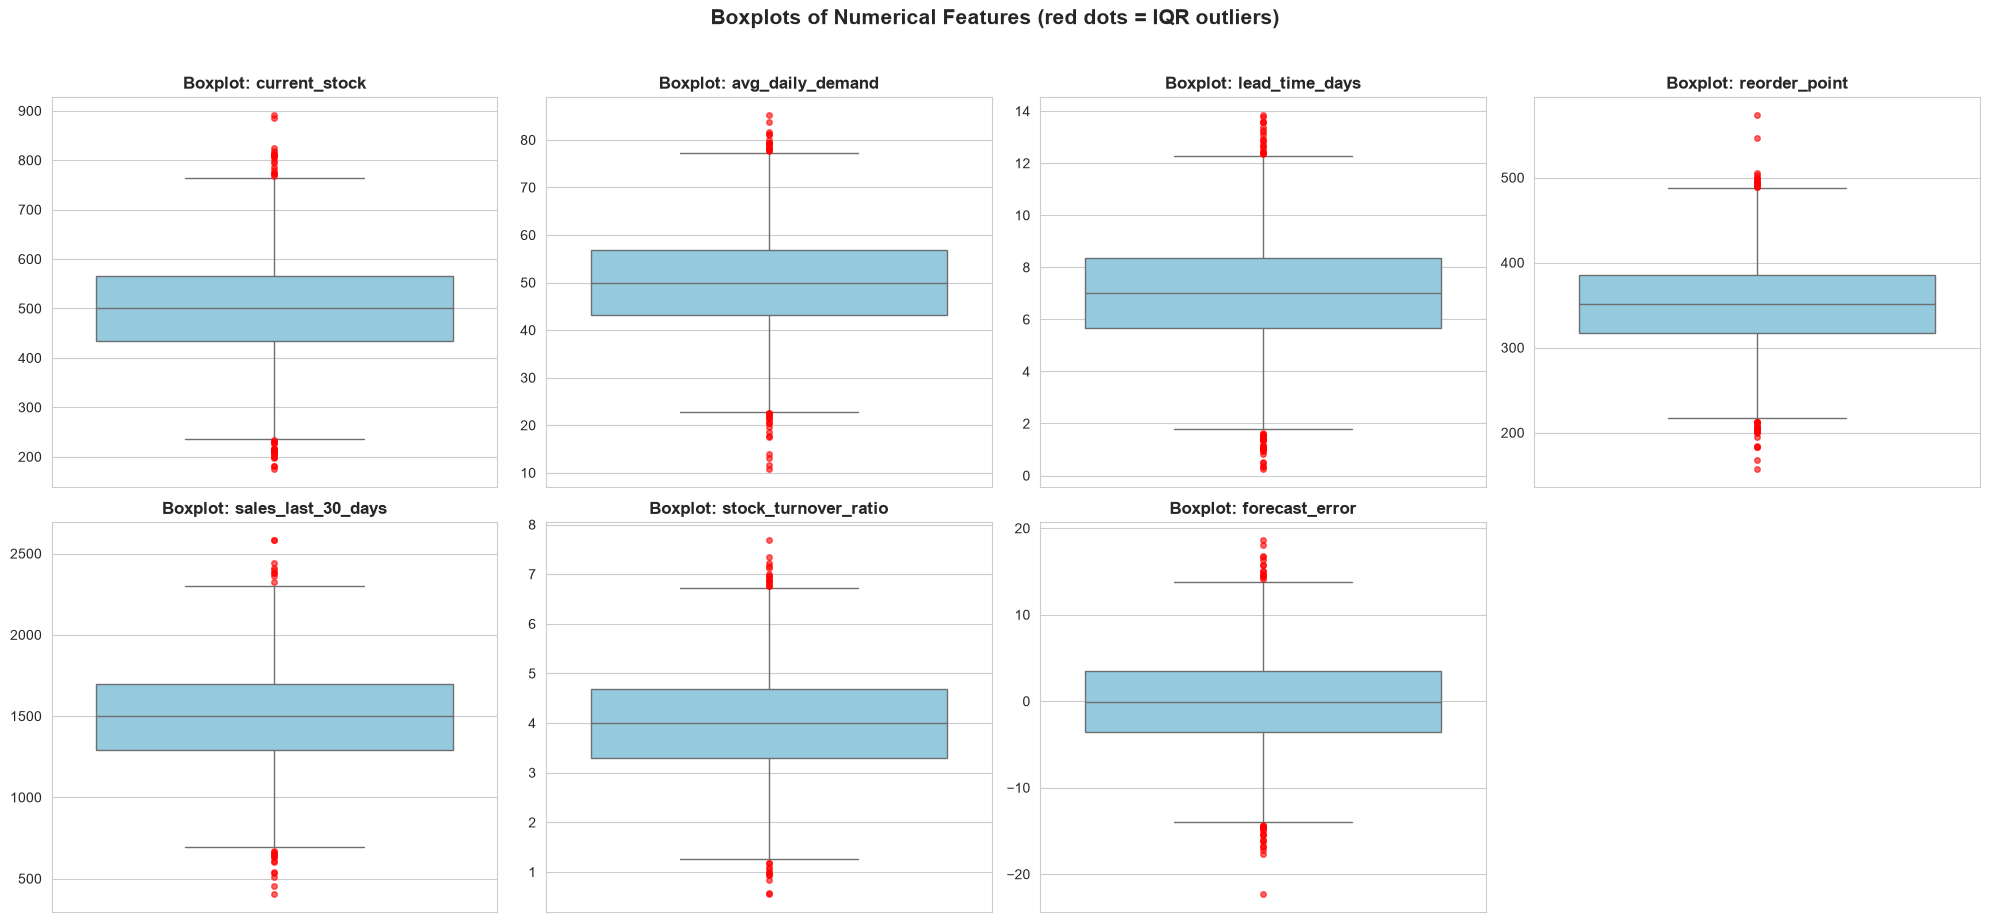

In [60]:
#  VISUAL DETECTION: BOXPLOTS

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df_out[col], ax=axes[i], color="skyblue",
                flierprops=dict(marker="o", markerfacecolor="red",
                                markeredgecolor="red", markersize=4, alpha=0.6))
    axes[i].set_title(f"Boxplot: {col}", fontsize=12, fontweight="bold")
    axes[i].set_ylabel("")

axes[-1].axis("off")           # 7 plots in a 2x4 grid -> hide the empty one
plt.suptitle("Boxplots of Numerical Features (red dots = IQR outliers)",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

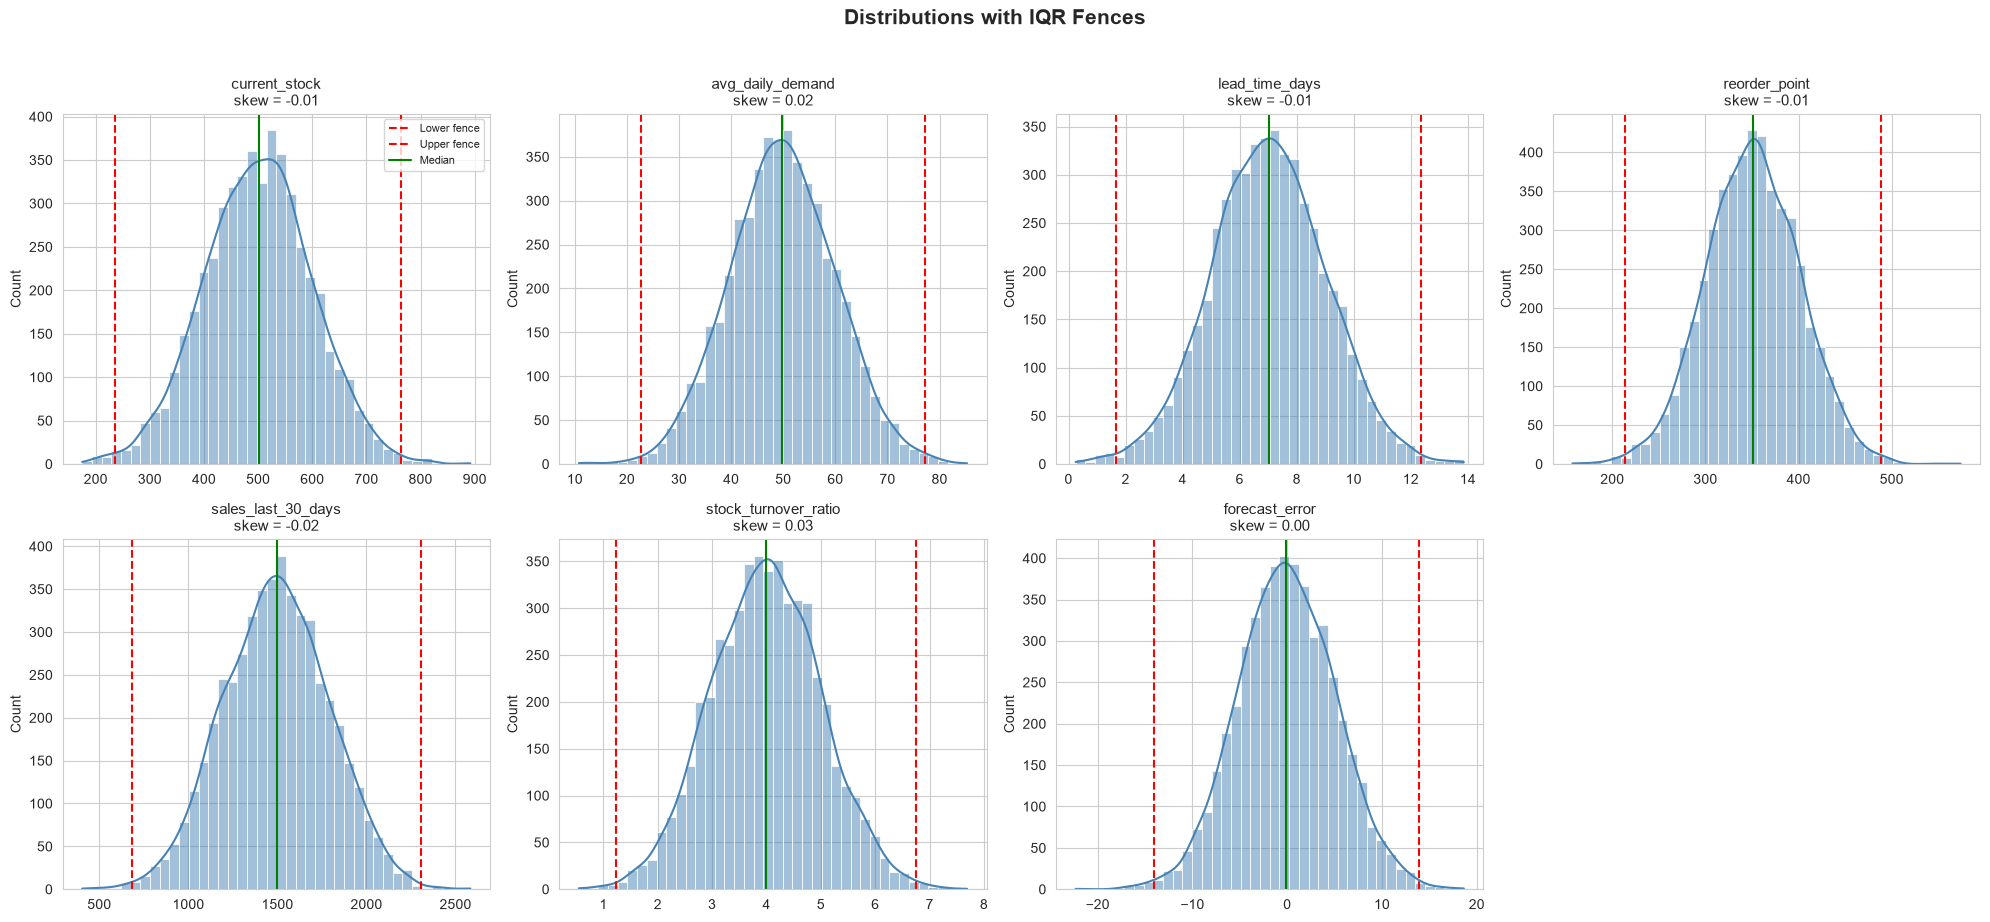

In [61]:
#  DISTRIBUTION PLOTS WITH IQR FENCES

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    _, _, _, lo, hi = iqr_bounds(df_out[col])
    sns.histplot(df_out[col], kde=True, ax=axes[i], color="steelblue", bins=40)
    axes[i].axvline(lo, color="red", linestyle="--", label="Lower fence")
    axes[i].axvline(hi, color="red", linestyle="--", label="Upper fence")
    axes[i].axvline(df_out[col].median(), color="green", linestyle="-", label="Median")
    axes[i].set_title(f"{col}\nskew = {df_out[col].skew():.2f}", fontsize=11)
    axes[i].set_xlabel("")
    if i == 0:
        axes[i].legend(fontsize=8)

axes[-1].axis("off")
plt.suptitle("Distributions with IQR Fences", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

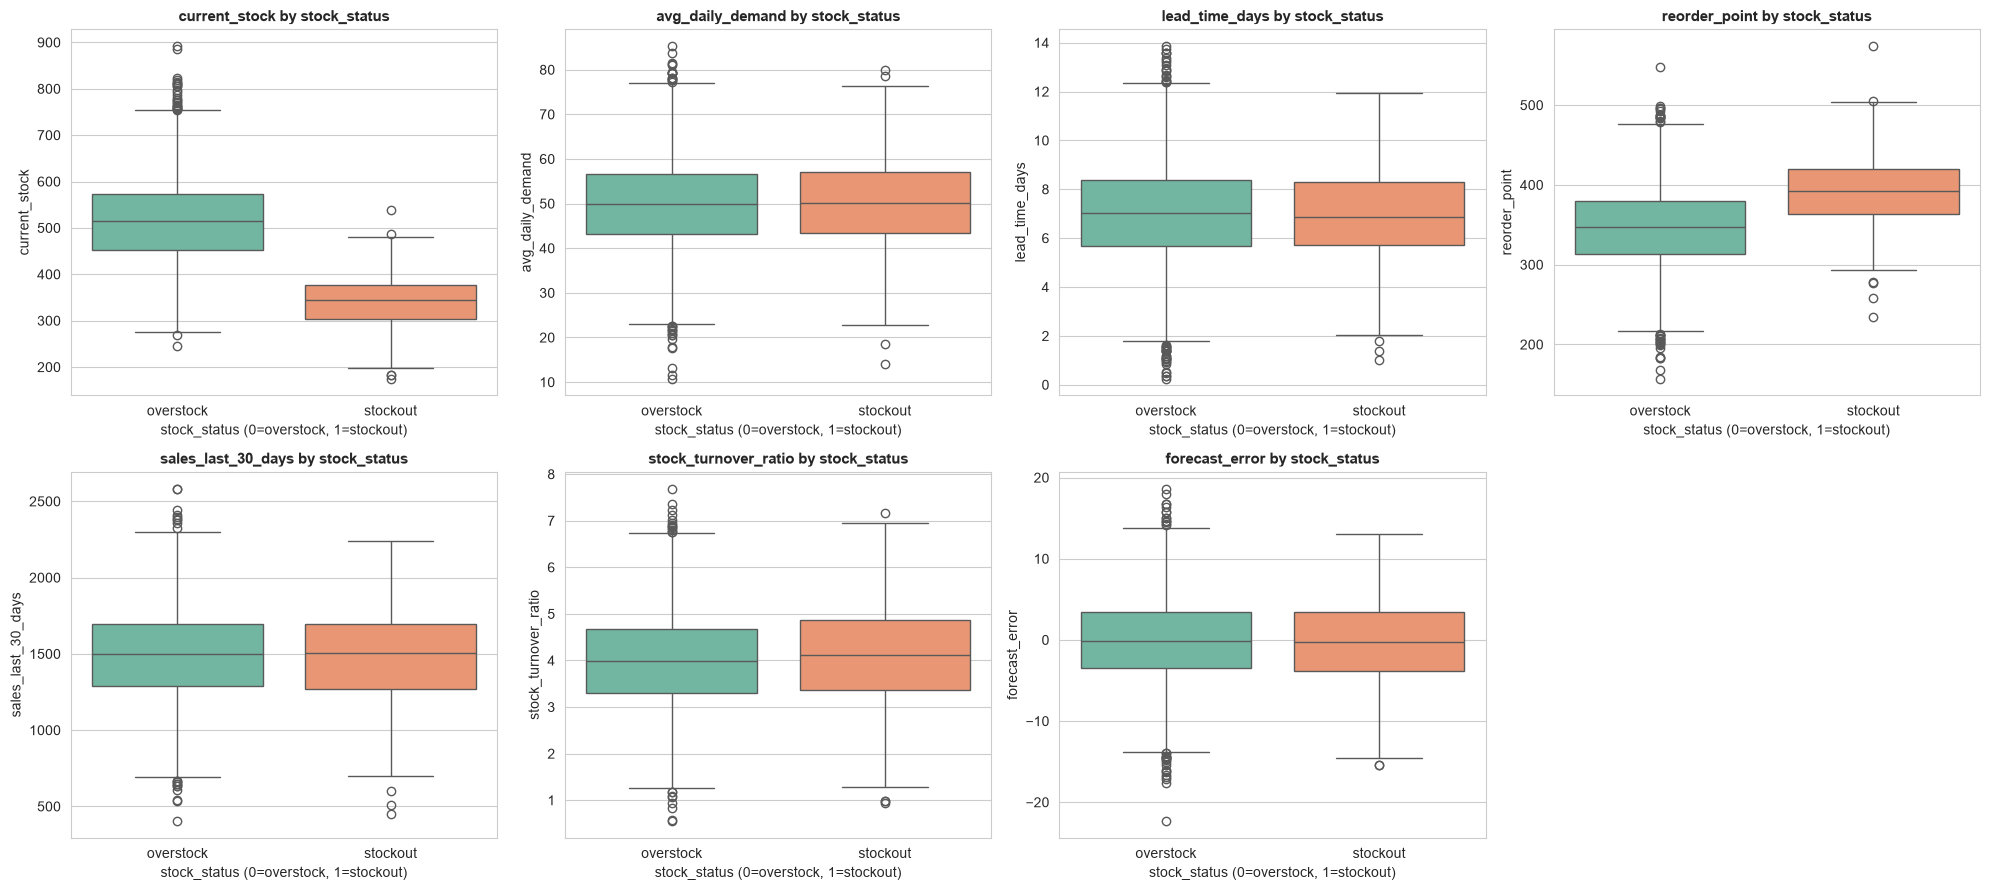

In [62]:
#  BOXPLOTS BY TARGET (stock_status: 0 = overstock, 1 = stockout)
#    Shows whether extreme values are concentrated in one class.

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x="stock_status", y=col, data=df_out, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{col} by stock_status", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("stock_status (0=overstock, 1=stockout)")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [63]:

# INVESTIGATION STEP 1: DOMAIN / LOGICAL VALIDITY RULES
#    An outlier that is IMPOSSIBLE in the real world is an ERROR.
#    (negative stock, zero/negative demand or lead time, etc.)
#    forecast_error may legitimately be negative (under-forecast)
# Requires Cells 1-5 to have been run (num_cols, iqr_bounds, flags, z_df, mz_df).

rules = {
    "current_stock":        lambda s: s < 0,
    "avg_daily_demand":     lambda s: s <= 0,
    "lead_time_days":       lambda s: s <= 0,
    "reorder_point":        lambda s: s <= 0,
    "sales_last_30_days":   lambda s: s < 0,
    "stock_turnover_ratio": lambda s: s < 0,
}

# --- Cross-feature consistency (from Cell 10) ---
safe_den_rop   = (df_out["avg_daily_demand"] * df_out["lead_time_days"]).replace(0, np.nan)
safe_den_sales = (df_out["avg_daily_demand"] * 30).replace(0, np.nan)

df_out["rop_ratio"]   = df_out["reorder_point"] / safe_den_rop
df_out["sales_ratio"] = df_out["sales_last_30_days"] / safe_den_sales

ratio_extreme = {}
for r in ["rop_ratio", "sales_ratio"]:
    rs = df_out[r].replace([np.inf, -np.inf], np.nan)
    _, _, _, lo3, hi3 = iqr_bounds(rs.dropna(), 3.0)
    ratio_extreme[r] = ((rs < lo3) | (rs > hi3)).fillna(False)

check_map = {
    "avg_daily_demand":   ["rop_ratio", "sales_ratio"],
    "lead_time_days":     ["rop_ratio"],
    "reorder_point":      ["rop_ratio"],
    "sales_last_30_days": ["sales_ratio"],
}

# --- Make sure the any_outlier column exists (used later in Cells 11, 12, 16) ---
df_out["n_outlier_features"] = iqr_flags.sum(axis=1)
df_out["any_outlier"]        = df_out["n_outlier_features"] > 0

print("Patch applied.")
print("check_map defined for:", list(check_map.keys()))
print("Extreme ratio records:", {k: int(v.sum()) for k, v in ratio_extreme.items()})

Patch applied.
check_map defined for: ['avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days']
Extreme ratio records: {'rop_ratio': 85, 'sales_ratio': 15}


In [64]:
#  INVESTIGATION STEP 1: DOMAIN / LOGICAL VALIDITY RULES
#    An outlier that is IMPOSSIBLE in the real world is an ERROR.
#    (negative stock, zero/negative demand or lead time, etc.)
#    forecast_error may legitimately be negative (under-forecast).

rules = {
    "current_stock":        lambda s: s < 0,
    "avg_daily_demand":     lambda s: s <= 0,
    "lead_time_days":       lambda s: s <= 0,
    "reorder_point":        lambda s: s <= 0,
    "sales_last_30_days":   lambda s: s < 0,
    "stock_turnover_ratio": lambda s: s < 0,
}

domain_rows = []
for col in num_cols:
    s = df_out[col]
    n_nonfinite = int((~np.isfinite(s)).sum())
    n_invalid   = int(rules[col](s).sum()) if col in rules else 0
    domain_rows.append({
        "feature": col,
        "min": s.min(), "max": s.max(),
        "impossible_values": n_invalid,
        "non_finite_values": n_nonfinite,
    })

domain_check = pd.DataFrame(domain_rows).set_index("feature")
print("DOMAIN-RULE VALIDATION")
display(domain_check)

if (domain_check[["impossible_values", "non_finite_values"]].sum().sum()) == 0:
    print("\nNo impossible values found: every outlier must be judged on plausibility.")
else:
    print("\nImpossible values exist -> these will be classified as DATA ERRORS.")

DOMAIN-RULE VALIDATION


,min,max,impossible_values,non_finite_values
feature,,,,
current_stock,175.00,892.00,0,0
avg_daily_demand,10.78,85.29,0,0
lead_time_days,0.25,13.86,0,0
reorder_point,157.18,573.95,0,0
sales_last_30_days,403.47,2583.41,0,0
stock_turnover_ratio,0.55,7.69,0,0
forecast_error,-22.33,18.64,0,0



No impossible values found: every outlier must be judged on plausibility.


In [65]:
#  INVESTIGATION STEP 3: MULTIVARIATE CHECK (Isolation Forest)
#     Finds records that look unusual in COMBINATION of features
#     even if no single value is extreme.

from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=42)
df_out["iso_outlier"] = (iso.fit_predict(df_out[num_cols]) == -1)

print("Isolation Forest multivariate outliers:", int(df_out["iso_outlier"].sum()))

overlap = (df_out["iso_outlier"] & df_out["any_outlier"]).sum()
print(f"Of these, also univariate IQR outliers: {overlap}")
print(f"Multivariate-only (not caught by IQR): {int(df_out['iso_outlier'].sum() - overlap)}")

display(df_out.loc[df_out["iso_outlier"], orig_cols].head(15))

Isolation Forest multivariate outliers: 50
Of these, also univariate IQR outliers: 23
Multivariate-only (not caught by IQR): 27


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
220,731,67.85,9.63,358.97,1938.76,2.07,-2.00,peak,essential,low,overstock
224,452,79.36,9.55,365.41,1502.23,2.95,-17.66,peak,essential,low,overstock
438,329,53.42,10.23,355.04,1586.92,0.98,13.05,off-peak,essential,high,stockout
447,406,67.68,4.90,250.55,899.48,6.49,-4.52,peak,non-essential,low,overstock
478,807,45.18,10.80,430.47,894.05,2.98,6.58,off-peak,non-essential,high,overstock
507,413,24.68,3.23,337.02,2022.86,6.08,1.97,peak,non-essential,low,overstock
564,620,50.31,11.60,446.24,2106.36,5.37,6.34,off-peak,essential,high,overstock
777,475,46.44,6.39,343.57,657.38,0.94,-11.83,off-peak,non-essential,low,overstock
796,496,80.98,3.19,334.27,904.93,5.16,-10.30,off-peak,essential,high,overstock
843,538,28.76,8.18,573.95,1905.83,5.50,5.95,peak,essential,high,stockout


In [66]:
#  INVESTIGATION STEP 4: DO OUTLIERS RELATE TO THE TARGET?
#     If outliers are linked to stockout / overstock, they likely carry
#     real information (genuine) and removing them would hurt the model.

ct = pd.crosstab(df_out["any_outlier"], df_out["stock_status"])
ct.index = ["No outlier", "Has outlier"] if len(ct) == 2 else ct.index
print("Outlier presence vs stock_status (0=overstock, 1=stockout):")
display(ct)

print("\nRow-wise % distribution:")
display((pd.crosstab(df_out["any_outlier"], df_out["stock_status"], normalize="index") * 100).round(2))

if ct.shape == (2, 2):
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df_out["any_outlier"], df_out["stock_status"]))
    print(f"\nChi-square test: chi2 = {chi2:.3f}, p-value = {p:.4f}")
    print("-> Outliers ARE significantly associated with the target (likely informative)."
          if p < 0.05 else
          "-> No significant association with the target.")

print("\nMean of each feature by outlier presence:")
display(df_out.groupby("any_outlier")[num_cols].mean().round(2))

Outlier presence vs stock_status (0=overstock, 1=stockout):


stock_status,overstock,stockout
No outlier,4356,407
Has outlier,187,50



Row-wise % distribution:


stock_status,overstock,stockout
any_outlier,,
False,91.45,8.55
True,78.90,21.10



Chi-square test: chi2 = 41.334, p-value = 0.0000
-> Outliers ARE significantly associated with the target (likely informative).

Mean of each feature by outlier presence:


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error
any_outlier,,,,,,,
False,500.16,49.96,7.03,350.93,1496.47,3.99,-0.01
True,498.10,48.70,6.79,348.65,1454.87,3.98,-0.97


In [67]:
# CLASSIFY EVERY OUTLIER: GENUINE / SUSPECT / ERROR
#
#  ERROR   : violates a domain rule (impossible value)
#  SUSPECT : extreme (beyond 3xIQR) AND
#              - breaks a related-feature relationship, OR
#              - (no related feature) flagged by IQR + Z-score + Modified Z together
#  GENUINE : everything else (plausible, consistent extreme value)

records = []

for col in num_cols:
    mask = iqr_flags[col] | z_flags[col] | mz_flags[col]       # flagged by >= 1 method
    idx = df_out.index[mask]
    if len(idx) == 0:
        continue

    sub = pd.DataFrame({
        "row": idx,
        "feature": col,
        "value": df_out.loc[idx, col].values,
        "z_score": z_df.loc[idx, col].values,
        "mod_z": mz_df.loc[idx, col].values,
        "iqr_flag": iqr_flags.loc[idx, col].values,
        "z_flag": z_flags.loc[idx, col].values,
        "mz_flag": mz_flags.loc[idx, col].values,
        "iqr_extreme": iqr_extreme_flags.loc[idx, col].values,
    })
    sub["n_methods"] = sub[["iqr_flag", "z_flag", "mz_flag"]].sum(axis=1)

    # domain error?
    sub["domain_error"] = rules[col](df_out.loc[idx, col]).values if col in rules else False

    # consistency check
    if col in check_map:
        broken = np.zeros(len(idx), dtype=bool)
        for r in check_map[col]:
            broken |= ratio_extreme[r].loc[idx].values
        sub["has_check"] = True
        sub["breaks_relation"] = broken
    else:
        sub["has_check"] = False
        sub["breaks_relation"] = False

    records.append(sub)

outlier_log = pd.concat(records, ignore_index=True)

cond_error   = outlier_log["domain_error"]
cond_sus_rel = outlier_log["has_check"] & outlier_log["iqr_extreme"] & outlier_log["breaks_relation"]
cond_sus_mag = (~outlier_log["has_check"]) & outlier_log["iqr_extreme"] & \
               (outlier_log["z_score"].abs() > Z_THRESH) & (outlier_log["mod_z"].abs() > MZ_THRESH)

outlier_log["verdict"] = np.select(
    [cond_error, cond_sus_rel | cond_sus_mag],
    ["Error", "Suspect"],
    default="Genuine",
)

outlier_log["reason"] = np.select(
    [cond_error, cond_sus_rel, cond_sus_mag],
    ["Impossible value (domain rule violated)",
     "Extreme AND inconsistent with related features",
     "Extreme by IQR, Z-score and Modified Z-score together"],
    default="Plausible value, consistent with related features",
)

print("Total flagged outlier values:", len(outlier_log))
print("\nVerdict counts:")
display(outlier_log["verdict"].value_counts().to_frame("count"))

print("\nVerdict by feature:")
verdict_table = pd.crosstab(outlier_log["feature"], outlier_log["verdict"])
for v in ["Error", "Suspect", "Genuine"]:
    if v not in verdict_table.columns:
        verdict_table[v] = 0
verdict_table = verdict_table[["Error", "Suspect", "Genuine"]]
verdict_table["Total"] = verdict_table.sum(axis=1)
display(verdict_table)

print("\nSample of the outlier log (most extreme first):")
display(outlier_log.sort_values("z_score", key=np.abs, ascending=False).head(20).round(3))

Total flagged outlier values: 243

Verdict counts:


,count
verdict,
Genuine,243



Verdict by feature:


verdict,Error,Suspect,Genuine,Total
feature,,,,
avg_daily_demand,0,0,34,34
current_stock,0,0,42,42
forecast_error,0,0,34,34
lead_time_days,0,0,48,48
reorder_point,0,0,36,36
sales_last_30_days,0,0,23,23
stock_turnover_ratio,0,0,26,26



Sample of the outlier log (most extreme first):


,row,feature,value,z_score,mod_z,iqr_flag,z_flag,mz_flag,iqr_extreme,n_methods,domain_error,has_check,breaks_relation,verdict,reason
132,843,reorder_point,573.95,4.448,4.389,True,True,True,False,3,False,True,False,Genuine,"Plausible value, consistent with related features"
225,2541,forecast_error,-22.33,-4.343,-4.280,True,True,True,False,3,False,False,False,Genuine,"Plausible value, consistent with related features"
21,2895,current_stock,892.00,3.934,3.996,True,True,True,False,3,False,False,False,Genuine,"Plausible value, consistent with related features"
151,3851,reorder_point,547.12,3.913,3.861,True,True,True,False,3,False,True,False,Genuine,"Plausible value, consistent with related features"
75,4770,avg_daily_demand,10.78,-3.872,-3.847,True,True,True,False,3,False,True,True,Genuine,"Plausible value, consistent with related features"
1,209,current_stock,885.00,3.863,3.924,True,True,True,False,3,False,False,False,Genuine,"Plausible value, consistent with related features"
157,4674,reorder_point,157.18,-3.860,-3.814,True,True,True,False,3,False,True,False,Genuine,"Plausible value, consistent with related features"
68,3200,avg_daily_demand,11.63,-3.788,-3.764,True,True,True,False,3,False,True,True,Genuine,"Plausible value, consistent with related features"
202,3552,stock_turnover_ratio,7.69,3.699,3.607,True,True,True,False,3,False,False,False,Genuine,"Plausible value, consistent with related features"
170,2494,sales_last_30_days,403.47,-3.699,-3.642,True,True,True,False,3,False,True,False,Genuine,"Plausible value, consistent with related features"


In [68]:
#  TREATMENT
#   ERROR   -> replace with median of the clean values (or drop the row if you prefer)
#   SUSPECT -> winsorize (cap) at the IQR fences, so the record is kept but its
#              influence is limited
#   GENUINE -> KEEP unchanged (real risk signal; removing it would bias the model)
#
#   Also builds df_winsor (all IQR outliers capped), which is an option for
#   linear / distance-based models.

CAP_K = 1.5          # fence multiplier used for capping

df_treated = df_out[orig_cols].copy()
df_treated[num_cols] = df_treated[num_cols].astype(float)

# --- ERRORS: median imputation ---
err = outlier_log[outlier_log["verdict"] == "Error"]
for col, g in err.groupby("feature"):
    clean_median = df_out.loc[~df_out.index.isin(g["row"]), col].median()
    df_treated.loc[g["row"].values, col] = clean_median
print("Errors imputed:", len(err))

# --- SUSPECT: winsorize at IQR fences ---
sus = outlier_log[outlier_log["verdict"] == "Suspect"]
for col, g in sus.groupby("feature"):
    _, _, _, lo, hi = iqr_bounds(df_out[col], CAP_K)
    df_treated.loc[g["row"].values, col] = df_treated.loc[g["row"].values, col].clip(lo, hi)
print("Suspect values capped:", len(sus))

# --- GENUINE: kept as is ---
gen = outlier_log[outlier_log["verdict"] == "Genuine"]
print("Genuine values retained:", len(gen))

# --- Alternative version: cap ALL IQR outliers (for linear / distance-based models) ---
df_winsor = df_treated.copy()
for col in num_cols:
    _, _, _, lo, hi = iqr_bounds(df_out[col], CAP_K)
    df_winsor[col] = df_winsor[col].clip(lo, hi)

# --- Integrity checks ---
print("\nShape df_treated:", df_treated.shape, "| df_winsor:", df_winsor.shape)
print("Missing values in df_treated:", int(df_treated.isnull().sum().sum()))

# --- Decision table per feature ---
def decide(row):
    if row["Error"] > 0:
        return "Fix errors (median imputation); keep genuine values"
    if row["Suspect"] > 0:
        return "Cap suspect values at IQR fences; keep genuine values"
    return "Retain all (genuine extremes)"

decision_table = verdict_table.copy()
decision_table["Treatment decision"] = decision_table.apply(decide, axis=1)
print("\nTREATMENT DECISIONS")
display(decision_table)

Errors imputed: 0
Suspect values capped: 0
Genuine values retained: 243

Shape df_treated: (5000, 11) | df_winsor: (5000, 11)
Missing values in df_treated: 0

TREATMENT DECISIONS


verdict,Error,Suspect,Genuine,Total,Treatment decision
feature,,,,,
avg_daily_demand,0,0,34,34,Retain all (genuine extremes)
current_stock,0,0,42,42,Retain all (genuine extremes)
forecast_error,0,0,34,34,Retain all (genuine extremes)
lead_time_days,0,0,48,48,Retain all (genuine extremes)
reorder_point,0,0,36,36,Retain all (genuine extremes)
sales_last_30_days,0,0,23,23,Retain all (genuine extremes)
stock_turnover_ratio,0,0,26,26,Retain all (genuine extremes)


,mean_before,mean_after,std_before,std_after,skew_before,skew_after,max_before,max_after,min_before,min_after
feature,,,,,,,,,,
current_stock,500.066,500.066,99.648,99.648,-0.012,-0.012,892.00,892.00,175.00,175.00
avg_daily_demand,49.901,49.901,10.104,10.104,0.016,0.016,85.29,85.29,10.78,10.78
lead_time_days,7.021,7.021,1.998,1.998,-0.008,-0.008,13.86,13.86,0.25,0.25
reorder_point,350.826,350.826,50.167,50.167,-0.008,-0.008,573.95,573.95,157.18,157.18
sales_last_30_days,1494.494,1494.494,295.012,295.012,-0.015,-0.015,2583.41,2583.41,403.47,403.47
stock_turnover_ratio,3.993,3.993,0.999,0.999,0.029,0.029,7.69,7.69,0.55,0.55
forecast_error,-0.055,-0.055,5.130,5.130,0.001,0.001,18.64,18.64,-22.33,-22.33


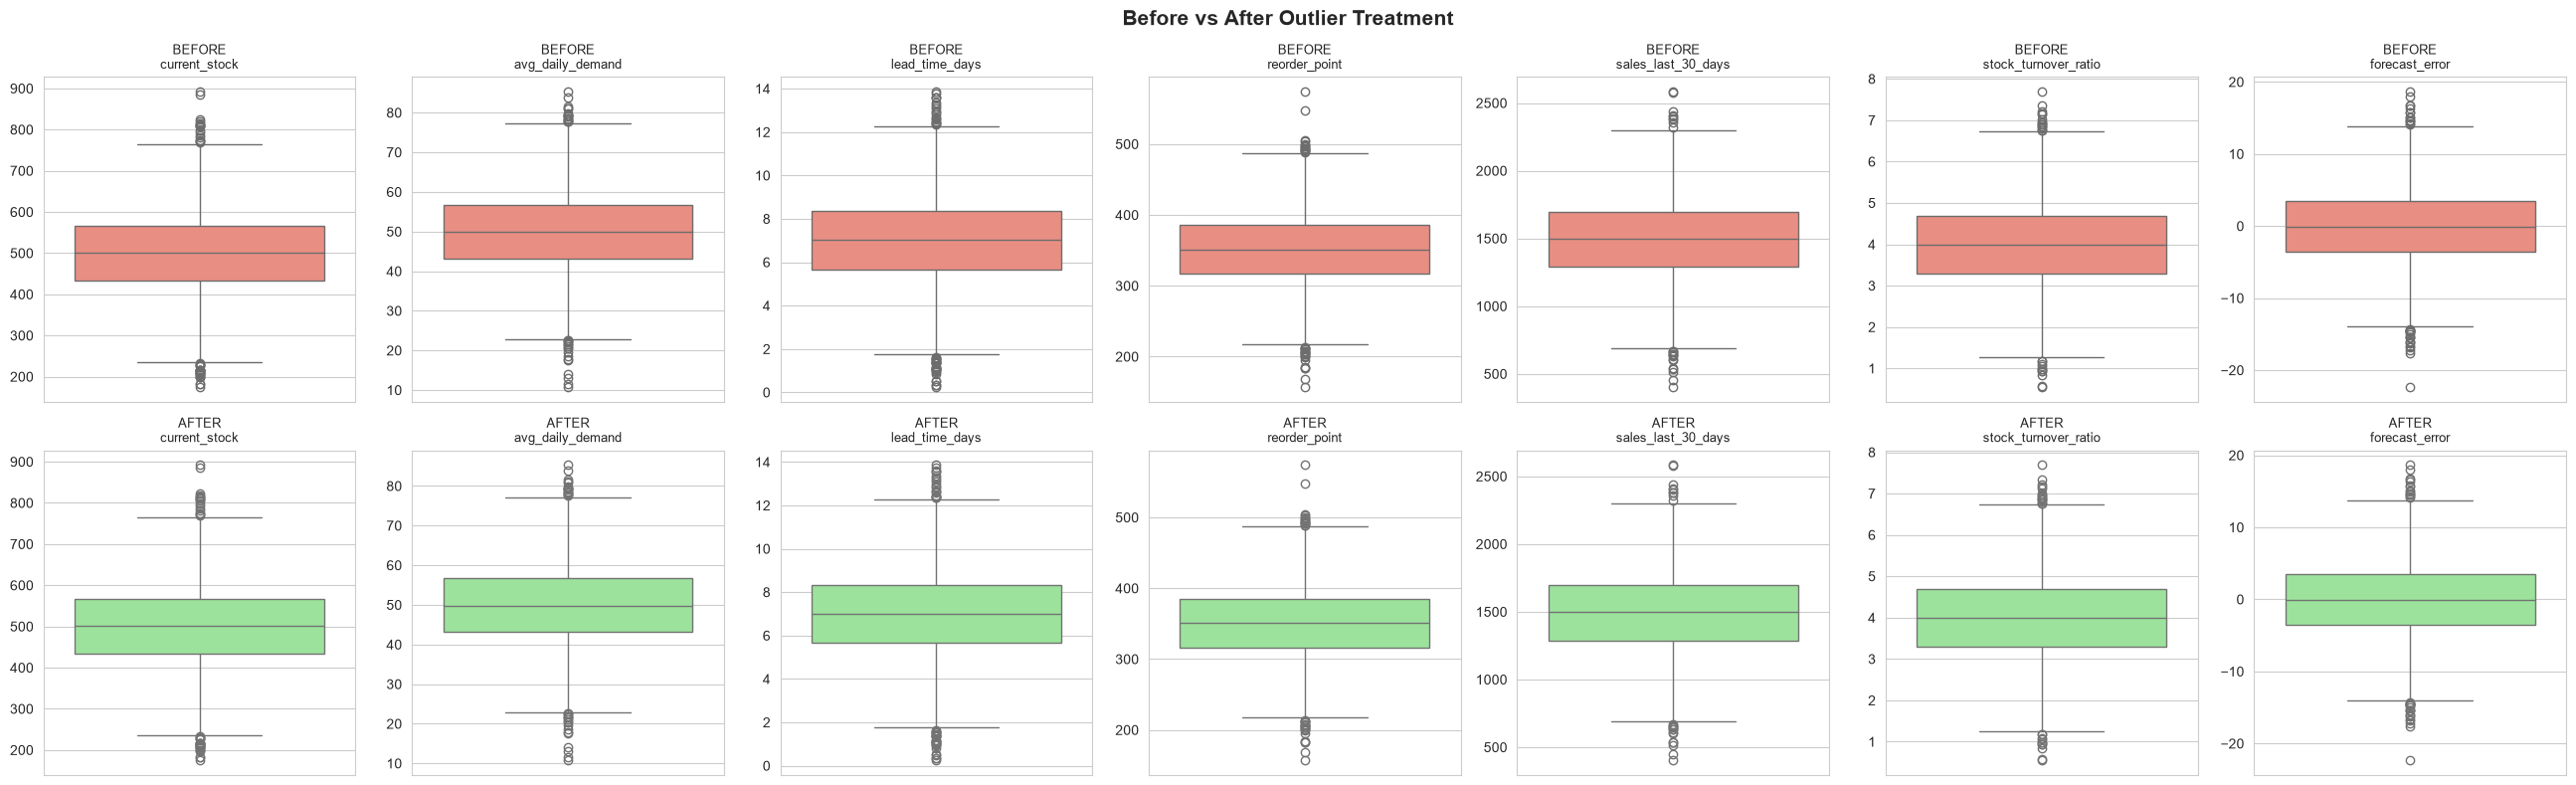

Remaining IQR outliers after treatment (genuine values kept on purpose):


,remaining_outliers
current_stock,42
avg_daily_demand,34
lead_time_days,48
reorder_point,36
sales_last_30_days,23
stock_turnover_ratio,26
forecast_error,34


In [69]:
#  BEFORE vs AFTER COMPARISON

cmp_rows = []
for col in num_cols:
    cmp_rows.append({
        "feature": col,
        "mean_before": df_out[col].mean(),     "mean_after": df_treated[col].mean(),
        "std_before": df_out[col].std(),       "std_after": df_treated[col].std(),
        "skew_before": df_out[col].skew(),     "skew_after": df_treated[col].skew(),
        "max_before": df_out[col].max(),       "max_after": df_treated[col].max(),
        "min_before": df_out[col].min(),       "min_after": df_treated[col].min(),
    })
display(pd.DataFrame(cmp_rows).set_index("feature").round(3))

# Boxplots: original vs treated
fig, axes = plt.subplots(2, 7, figsize=(26, 8))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df_out[col], ax=axes[0, i], color="salmon")
    axes[0, i].set_title(f"BEFORE\n{col}", fontsize=9)
    axes[0, i].set_ylabel("")
    sns.boxplot(y=df_treated[col], ax=axes[1, i], color="lightgreen")
    axes[1, i].set_title(f"AFTER\n{col}", fontsize=9)
    axes[1, i].set_ylabel("")
plt.suptitle("Before vs After Outlier Treatment", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Remaining IQR outliers after treatment (genuine ones intentionally kept)
remaining = {}
for col in num_cols:
    _, _, _, lo, hi = iqr_bounds(df_treated[col], 1.5)
    remaining[col] = int(((df_treated[col] < lo) | (df_treated[col] > hi)).sum())
print("Remaining IQR outliers after treatment (genuine values kept on purpose):")
display(pd.Series(remaining, name="remaining_outliers").to_frame())

In [70]:
#  FINAL OUTLIER REPORT (auto-generated from the results above)

total_cells   = len(df_out) * len(num_cols)
n_flag_values = len(outlier_log)
n_err, n_sus, n_gen = (int((outlier_log["verdict"] == v).sum()) for v in ["Error", "Suspect", "Genuine"])

print("=" * 70)
print("                    OUTLIER ANALYSIS REPORT")
print("=" * 70)
print(f"Dataset analysed        : {df_out.shape[0]} rows x {len(num_cols)} continuous features")
print(f"Methods used            : IQR (1.5x / 3x), Z-score (|z|>3), Modified Z (|Mz|>3.5),")
print(f"                          Boxplots, Isolation Forest (multivariate)")
print(f"Outlier values flagged  : {n_flag_values} ({n_flag_values/total_cells*100:.2f}% of all numeric cells)")
print(f"Records with >=1 outlier: {int(df_out['any_outlier'].sum())} ({df_out['any_outlier'].mean()*100:.2f}%)")
print("-" * 70)
print(f"Verdict -> ERROR: {n_err} | SUSPECT: {n_sus} | GENUINE: {n_gen}")
print("-" * 70)

for col in num_cols:
    sub = outlier_log[outlier_log["feature"] == col]
    _, _, _, lo, hi = iqr_bounds(df_out[col])
    print(f"\n[{col}]")
    print(f"  Valid IQR range : {lo:.2f} to {hi:.2f} | skew = {df_out[col].skew():.2f}")
    print(f"  Flagged         : {len(sub)}  "
          f"(Error {int((sub['verdict']=='Error').sum())}, "
          f"Suspect {int((sub['verdict']=='Suspect').sum())}, "
          f"Genuine {int((sub['verdict']=='Genuine').sum())})")
    print(f"  Decision        : {decision_table.loc[col, 'Treatment decision']}")

print("\n" + "=" * 70)
print("OVERALL TREATMENT STRATEGY")
print("=" * 70)
print("1. Genuine outliers  -> KEPT. They are plausible, consistent with related")
print("   features and represent real stock-risk behaviour (stockout/overstock).")
print("2. Suspect outliers  -> CAPPED at IQR fences (record kept, influence reduced).")
print("3. Error outliers    -> REPLACED with the clean median (no impossible values remain).")
print("4. No rows were deleted, so the dataset size is preserved (5000 rows).")
print("5. For tree-based models (RandomForest, XGBoost) use df_treated;")
print("   for linear / distance-based models (LogReg, SVM, KNN) consider df_winsor")
print("   and feature scaling (RobustScaler is recommended).")
print("=" * 70)

                    OUTLIER ANALYSIS REPORT
Dataset analysed        : 5000 rows x 7 continuous features
Methods used            : IQR (1.5x / 3x), Z-score (|z|>3), Modified Z (|Mz|>3.5),
                          Boxplots, Isolation Forest (multivariate)
Outlier values flagged  : 243 (0.69% of all numeric cells)
Records with >=1 outlier: 237 (4.74%)
----------------------------------------------------------------------
Verdict -> ERROR: 0 | SUSPECT: 0 | GENUINE: 243
----------------------------------------------------------------------

[current_stock]
  Valid IQR range : 236.00 to 764.00 | skew = -0.01
  Flagged         : 42  (Error 0, Suspect 0, Genuine 42)
  Decision        : Retain all (genuine extremes)

[avg_daily_demand]
  Valid IQR range : 22.67 to 77.24 | skew = 0.02
  Flagged         : 34  (Error 0, Suspect 0, Genuine 34)
  Decision        : Retain all (genuine extremes)

[lead_time_days]
  Valid IQR range : 1.67 to 12.36 | skew = -0.01
  Flagged         : 48  (Error 0, Suspe

In [71]:
# Run this only if you want the rest of the notebook to continue with the treated data.
# Original columns, encoded categoricals included, are preserved.
df_before_outlier_treatment = df.copy()   # backup
df = df_treated.copy()

print("Final shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
df.head()

Final shape: (5000, 11)
Missing values: 0
Duplicated rows: 0


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
0,549.0,45.76,5.64,342.83,1604.49,4.17,-9.90,peak,essential,low,overstock
1,486.0,45.47,6.39,348.37,1585.00,4.01,-5.27,peak,non-essential,high,overstock
2,564.0,32.04,5.81,353.21,1219.04,3.57,-2.94,off-peak,non-essential,high,overstock
3,652.0,46.70,7.22,397.34,1673.88,4.00,0.75,off-peak,essential,low,overstock
4,476.0,57.33,9.39,312.64,1052.98,4.49,5.12,peak,essential,high,overstock


## Outlier Analysis Conclusion
- IQR, Z-score, Modified Z-score, boxplots and Isolation Forest flagged 243 values (0.69% of numerical cells) in 237 records (4.74%). No value lies beyond 3 × IQR and none breaks a domain rule.
- All flagged values were classified as **genuine**. Records with an outlier have a much higher stockout rate (21.1% vs 8.6%, chi-square p < 0.001), so they carry real risk signal.
- **Decision:** no rows were removed, replaced or capped. The dataset keeps all 5,000 rows; `df_winsor` (capped version) is available if a linear or distance-based model is sensitive to tails.

# Feature Relationships & Final Preprocessing

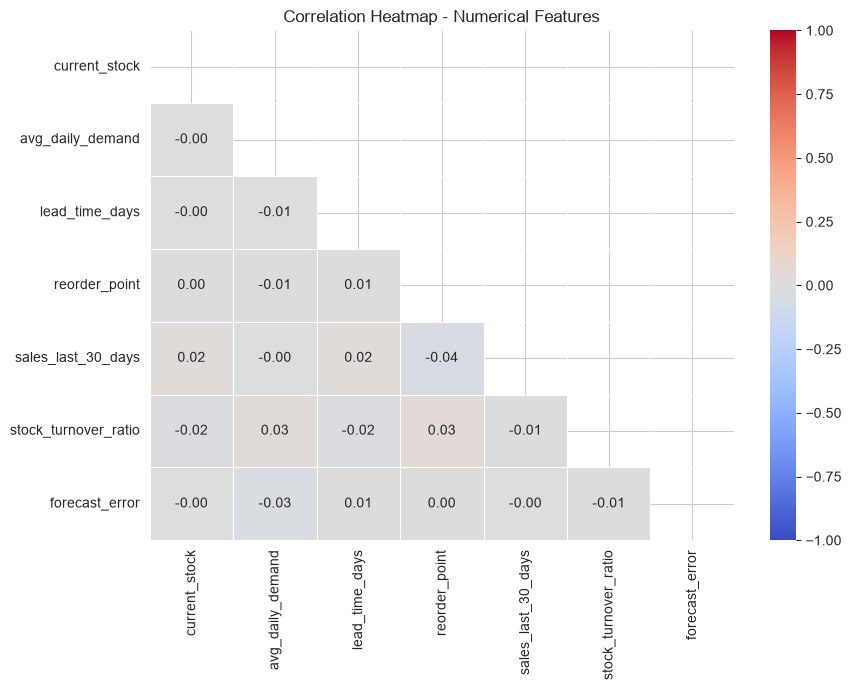

Strongest feature-feature correlations:


correlation  abs_correlation
sales_last_30_days   reorder_point          -0.036            0.036
stock_turnover_ratio reorder_point           0.035            0.035
                     avg_daily_demand        0.030            0.030
forecast_error       avg_daily_demand       -0.025            0.025
stock_turnover_ratio lead_time_days         -0.023            0.023

Pairs with |r| > 0.5: 0


In [72]:
# ---------- 1. Correlation analysis (numerical features) ----------
from scipy import stats

num_cols = ["current_stock", "avg_daily_demand", "lead_time_days", "reorder_point",
            "sales_last_30_days", "stock_turnover_ratio", "forecast_error"]
cat_cols = ["season", "item_category", "supplier_reliability"]
y_flag = (df["stock_status"] == "stockout").astype(int)      # 1 = stockout

corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap - Numerical Features")
plt.tight_layout()
plt.show()

pairs = corr.where(~mask).stack().rename("correlation").to_frame()
pairs["abs_correlation"] = pairs["correlation"].abs()
print("Strongest feature-feature correlations:")
display(pairs.sort_values("abs_correlation", ascending=False).head(5).round(3))
print("Pairs with |r| > 0.5:", int((pairs["abs_correlation"] > 0.5).sum()))

,type,test,corr_with_stockout,strength,p_value,significant (p<0.05)
feature,,,,,,
current_stock,numerical,Mann-Whitney U,-0.5143,0.5143,0.0000,True
reorder_point,numerical,Mann-Whitney U,0.2625,0.2625,0.0000,True
stock_turnover_ratio,numerical,Mann-Whitney U,0.0248,0.0248,0.0268,True
forecast_error,numerical,Mann-Whitney U,-0.0120,0.0120,0.4638,False
lead_time_days,numerical,Mann-Whitney U,-0.0099,0.0099,0.5039,False
sales_last_30_days,numerical,Mann-Whitney U,-0.0098,0.0098,0.7301,False
supplier_reliability,categorical,Chi-square,NaN,0.0073,0.6043,False
avg_daily_demand,numerical,Mann-Whitney U,0.0036,0.0036,0.7774,False
item_category,categorical,Chi-square,NaN,0.0034,0.8094,False


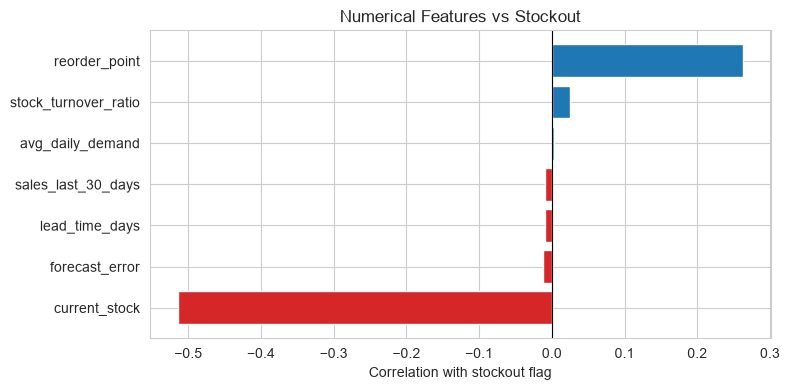

In [73]:
# ---------- 2. Feature-target relationships ----------
rows = []
for c in num_cols:
    _, p = stats.mannwhitneyu(df.loc[y_flag == 1, c], df.loc[y_flag == 0, c])
    rows.append({"feature": c, "type": "numerical", "test": "Mann-Whitney U",
                 "corr_with_stockout": df[c].corr(y_flag), "strength": abs(df[c].corr(y_flag)), "p_value": p})

for c in cat_cols:
    ct = pd.crosstab(df[c], y_flag)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))          # Cramer's V
    rows.append({"feature": c, "type": "categorical", "test": "Chi-square",
                 "corr_with_stockout": np.nan, "strength": v, "p_value": p})

assoc = pd.DataFrame(rows).set_index("feature")
assoc["significant (p<0.05)"] = assoc["p_value"] < 0.05
display(assoc.sort_values("strength", ascending=False).round(4))

# Correlation with the stockout flag
plt.figure(figsize=(8, 4))
ordered = assoc.loc[num_cols, "corr_with_stockout"].sort_values()
plt.barh(ordered.index, ordered.values, color=["tab:red" if v < 0 else "tab:blue" for v in ordered.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with stockout flag")
plt.title("Numerical Features vs Stockout")
plt.tight_layout()
plt.show()

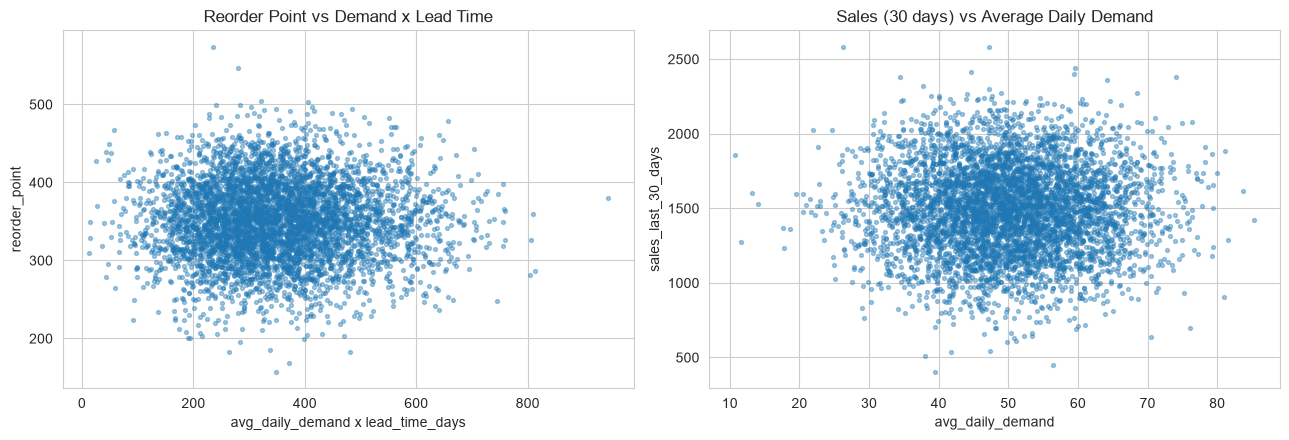

corr(reorder_point, demand x lead_time): 0.003
corr(sales_last_30_days, avg_daily_demand): -0.005

Engineered features vs stockout (compare: current_stock = -0.514, reorder_point = 0.262)


,corr_with_stockout,corr_with_current_stock
stock_minus_reorder,-0.578,0.893
stock_to_reorder_ratio,-0.510,0.783
days_of_cover,-0.322,0.631


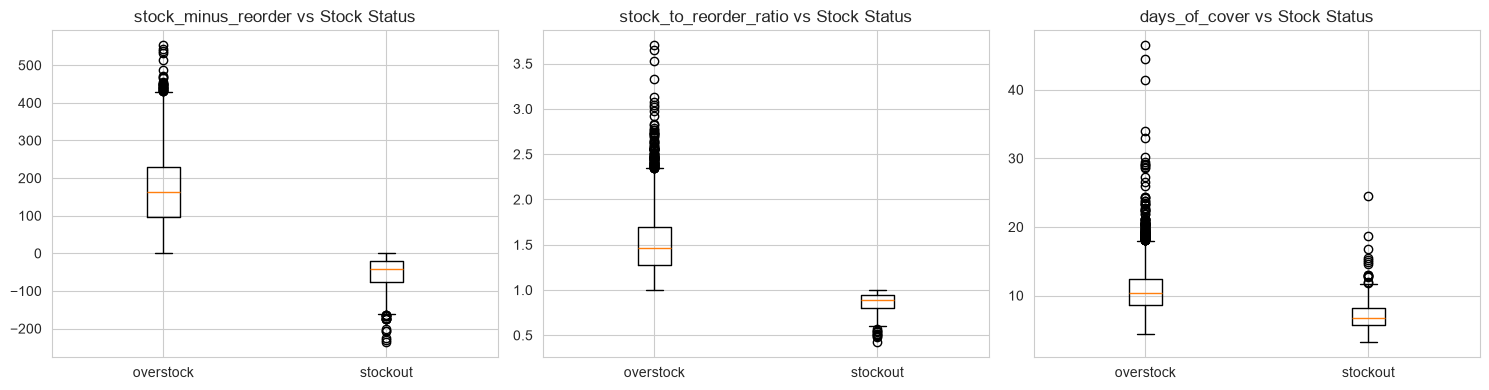

In [74]:
# ---------- 3. Feature-feature relationships ----------
# Expected business relationships: reorder_point ~ demand x lead time, sales_30d ~ 30 x demand
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df["avg_daily_demand"] * df["lead_time_days"], df["reorder_point"], s=8, alpha=0.4)
axes[0].set_xlabel("avg_daily_demand x lead_time_days")
axes[0].set_ylabel("reorder_point")
axes[0].set_title("Reorder Point vs Demand x Lead Time")
axes[1].scatter(df["avg_daily_demand"], df["sales_last_30_days"], s=8, alpha=0.4)
axes[1].set_xlabel("avg_daily_demand")
axes[1].set_ylabel("sales_last_30_days")
axes[1].set_title("Sales (30 days) vs Average Daily Demand")
plt.tight_layout()
plt.show()

print("corr(reorder_point, demand x lead_time):", round(df["reorder_point"].corr(df["avg_daily_demand"] * df["lead_time_days"]), 3))
print("corr(sales_last_30_days, avg_daily_demand):", round(df["sales_last_30_days"].corr(df["avg_daily_demand"]), 3))

# Candidate engineered features built from the inventory position
def add_inventory_features(d):
    d = d.copy()
    d["stock_minus_reorder"]     = d["current_stock"] - d["reorder_point"]
    d["stock_to_reorder_ratio"]  = d["current_stock"] / d["reorder_point"]
    d["days_of_cover"]           = d["current_stock"] / d["avg_daily_demand"]
    return d

eng_cols = ["stock_minus_reorder", "stock_to_reorder_ratio", "days_of_cover"]
df_eng = add_inventory_features(df)

eng_corr = pd.DataFrame({
    "corr_with_stockout": [df_eng[c].corr(y_flag) for c in eng_cols],
    "corr_with_current_stock": [df_eng[c].corr(df_eng["current_stock"]) for c in eng_cols],
}, index=eng_cols)
print("\nEngineered features vs stockout (compare: current_stock = %.3f, reorder_point = %.3f)"
      % (df["current_stock"].corr(y_flag), df["reorder_point"].corr(y_flag)))
display(eng_corr.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, eng_cols):
    ax.boxplot([df_eng.loc[y_flag == 0, c], df_eng.loc[y_flag == 1, c]], tick_labels=["overstock", "stockout"])
    ax.set_title(f"{c} vs Stock Status")
plt.tight_layout()
plt.show()

In [75]:
# ---------- 4. Multicollinearity (VIF from the inverse correlation matrix) ----------
vif = pd.DataFrame({"feature": num_cols, "VIF": np.diag(np.linalg.inv(corr.values))})
vif["multicollinearity"] = pd.cut(vif["VIF"], [0, 5, 10, np.inf], labels=["Low (<5)", "Moderate (5-10)", "High (>10)"])
display(vif.set_index("feature").round(3))
print("Maximum VIF among the original numerical features:", round(vif["VIF"].max(), 3))

# The engineered features are linear combinations of the originals, so check them separately
eng_check = df_eng[["current_stock", "reorder_point", "stock_minus_reorder"]].corr()
print("\ncorr(stock_minus_reorder, current_stock) =", round(eng_check.loc["stock_minus_reorder", "current_stock"], 3))
print("corr(stock_minus_reorder, reorder_point)  =", round(eng_check.loc["stock_minus_reorder", "reorder_point"], 3))

,VIF,multicollinearity
feature,,
current_stock,1.001,Low (<5)
avg_daily_demand,1.002,Low (<5)
lead_time_days,1.001,Low (<5)
reorder_point,1.003,Low (<5)
sales_last_30_days,1.002,Low (<5)
stock_turnover_ratio,1.003,Low (<5)
forecast_error,1.001,Low (<5)


Maximum VIF among the original numerical features: 1.003

corr(stock_minus_reorder, current_stock) = 0.893
corr(stock_minus_reorder, reorder_point)  = -0.449


In [76]:
# ---------- 5. Categorical encoding ----------
df_model = add_inventory_features(df)

encoding_maps = {
    "season":               {"off-peak": 0, "peak": 1},
    "item_category":        {"non-essential": 0, "essential": 1},
    "supplier_reliability": {"low": 0, "high": 1},
}
for col, mapping in encoding_maps.items():
    df_model[col] = df_model[col].map(mapping)
df_model["stock_status"] = df_model["stock_status"].map({"overstock": 0, "stockout": 1})

assert df_model.isnull().sum().sum() == 0, "Encoding produced missing values"
print("Encoding maps:")
for col, mapping in {**encoding_maps, "stock_status": {"overstock": 0, "stockout": 1}}.items():
    print(f"  {col}: {mapping}")
print("\nModel-ready shape:", df_model.shape)
print("All columns numeric:", all(np.issubdtype(t, np.number) for t in df_model.dtypes))
df_model.head()

Encoding maps:
  season: {'off-peak': 0, 'peak': 1}
  item_category: {'non-essential': 0, 'essential': 1}
  supplier_reliability: {'low': 0, 'high': 1}
  stock_status: {'overstock': 0, 'stockout': 1}

Model-ready shape: (5000, 14)
All columns numeric: True


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status,stock_minus_reorder,stock_to_reorder_ratio,days_of_cover
0,549.0,45.76,5.64,342.83,1604.49,4.17,-9.90,1,1,0,0,206.17,1.601377,11.997378
1,486.0,45.47,6.39,348.37,1585.00,4.01,-5.27,1,0,1,0,137.63,1.395068,10.688366
2,564.0,32.04,5.81,353.21,1219.04,3.57,-2.94,0,0,1,0,210.79,1.596784,17.602996
3,652.0,46.70,7.22,397.34,1673.88,4.00,0.75,0,1,0,0,254.66,1.640912,13.961456
4,476.0,57.33,9.39,312.64,1052.98,4.49,5.12,1,1,1,0,163.36,1.522518,8.302808


In [77]:
# ---------- 6. Stratified split and scaling (scaler fitted on training data only) ----------
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_model.drop(columns="stock_status")
y = df_model["stock_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

scale_cols = num_cols + eng_cols                    # binary encoded columns are left as 0/1
scaler = StandardScaler().fit(X_train[scale_cols])

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Stockout rate  train: %.2f%%  test: %.2f%%" % (y_train.mean() * 100, y_test.mean() * 100))
print("\nScaled training features (mean ~ 0, std ~ 1):")
display(X_train_scaled[scale_cols].agg(["mean", "std"]).round(3))

Train: (4000, 13) | Test: (1000, 13)
Stockout rate  train: 9.15%  test: 9.10%

Scaled training features (mean ~ 0, std ~ 1):


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,stock_minus_reorder,stock_to_reorder_ratio,days_of_cover
mean,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Final Feature-Preparation Plan

In [78]:
# ---------- 7. Final feature-preparation plan ----------
plan = pd.DataFrame(index=num_cols + cat_cols + eng_cols)
plan["type"] = ["numerical"] * len(num_cols) + ["categorical"] * len(cat_cols) + ["engineered"] * len(eng_cols)
plan["strength_with_target"] = (list(assoc.loc[num_cols, "strength"]) + list(assoc.loc[cat_cols, "strength"])
                                + [abs(df_eng[c].corr(y_flag)) for c in eng_cols])
plan["VIF"] = list(vif["VIF"]) + [np.nan] * (len(cat_cols) + len(eng_cols))
plan["preparation"] = ["StandardScaler"] * len(num_cols) + ["Binary label encoding (0/1)"] * len(cat_cols) + ["StandardScaler"] * len(eng_cols)

def decide(feature, strength):
    if feature in eng_cols:
        return "Candidate - use with tree models; for linear models use instead of its two parent features"
    if strength >= 0.2:
        return "Keep - key predictor"
    if strength >= 0.05:
        return "Keep - moderate signal"
    return "Keep for now - no direct signal, test via feature importance"

plan["decision"] = [decide(f, s) for f, s in zip(plan.index, plan["strength_with_target"])]
display(plan.round(3))

,type,strength_with_target,VIF,preparation,decision
current_stock,numerical,0.514,1.001,StandardScaler,Keep - key predictor
avg_daily_demand,numerical,0.004,1.002,StandardScaler,"Keep for now - no direct signal, test via feat..."
lead_time_days,numerical,0.010,1.001,StandardScaler,"Keep for now - no direct signal, test via feat..."
reorder_point,numerical,0.262,1.003,StandardScaler,Keep - key predictor
sales_last_30_days,numerical,0.010,1.002,StandardScaler,"Keep for now - no direct signal, test via feat..."
stock_turnover_ratio,numerical,0.025,1.003,StandardScaler,"Keep for now - no direct signal, test via feat..."
forecast_error,numerical,0.012,1.001,StandardScaler,"Keep for now - no direct signal, test via feat..."
season,categorical,0.000,NaN,Binary label encoding (0/1),"Keep for now - no direct signal, test via feat..."
item_category,categorical,0.003,NaN,Binary label encoding (0/1),"Keep for now - no direct signal, test via feat..."
supplier_reliability,categorical,0.007,NaN,Binary label encoding (0/1),"Keep for now - no direct signal, test via feat..."


# Final Conclusion: EDA and Data Preprocessing

**Data quality.** The dataset has 5,000 records and 11 columns (7 numerical, 3 binary categorical and the target `stock_status`). All data types are valid, with no missing values and no duplicate records.

**Target.** `stock_status` is imbalanced: 4,543 overstock records (90.86%) against 457 stockout records (9.14%).

**Univariate EDA.** The numerical features are roughly symmetric and well centred (current stock ~500 units, demand ~50 units/day, lead time ~7 days, reorder point ~350, 30-day sales ~1,500, turnover ~4, forecast error ~0). The three categorical features are split almost 50/50, so none of them is imbalanced.

**Relationships with the target.** `current_stock` is the strongest predictor (r = -0.514) and `reorder_point` is second (r = +0.262): stockouts happen when stock is low relative to the reorder point. All other numerical features have |r| < 0.03, and the categorical features show no association with the target (chi-square p > 0.6, Cramér's V < 0.01; stockout rate about 9% in every category). The engineered inventory features describe this relationship better than either parent alone: `stock_minus_reorder` (r = -0.578), `stock_to_reorder_ratio` (r = -0.510) and `days_of_cover` (r = -0.322).

**Multicollinearity.** No pair of numerical features has |r| above 0.04 and the maximum VIF is 1.003, so there is no multicollinearity and no feature needs to be dropped for that reason. The expected business links (reorder point vs demand x lead time, sales vs demand) are also absent (r ~ 0), which means the predictive signal comes almost entirely from the inventory position (`current_stock` and `reorder_point`).

**Preprocessing decisions.**
- Missing values and duplicates: none found, nothing to fix.
- Outliers: 243 flagged values (0.69% of numerical cells) were all classified as genuine and kept, because records with outliers have a higher stockout rate (21.1% vs 8.6%, p < 0.001). No row was removed or altered.
- Encoding: the three binary categorical features and the target were label-encoded to 0/1 (`stockout` = 1).
- Scaling: `StandardScaler` for the numerical and engineered features, fitted on the training set only to avoid leakage.
- Split: stratified 80/20 train/test split (4,000 / 1,000 rows) with the stockout rate preserved (9.15% train, 9.10% test).

**Next steps for modelling.** Handle the class imbalance on the training data only (class weights or SMOTE), and evaluate with precision, recall, F1-score and PR-AUC/ROC-AUC instead of accuracy. Use scaled features for Logistic Regression, and test Random Forest and XGBoost, which can also use the unscaled data. For linear models, use the engineered features in place of their two parent features because they are linear combinations of them. The categorical features carry little signal and should be checked through feature importance.

## Week 2 - Model Building and Evaluation

### Logistic Regression (Member 1)

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [80]:
# Replace parent features with engineered features
features_to_drop = [
    "current_stock",
    "reorder_point",
    "avg_daily_demand"
]

X_train_lr = X_train_scaled.drop(
    columns=features_to_drop,
    errors="ignore"
).copy()

X_test_lr = X_test_scaled.drop(
    columns=features_to_drop,
    errors="ignore"
).copy()

# Confirm train and test columns match
assert list(X_train_lr.columns) == list(X_test_lr.columns)
assert X_train_lr.columns.is_unique

print("Training data shape:", X_train_lr.shape)
print("Testing data shape:", X_test_lr.shape)
print("\nFeatures used:")
print(X_train_lr.columns.tolist())

Training data shape: (4000, 10)
Testing data shape: (1000, 10)

Features used:
['lead_time_days', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error', 'season', 'item_category', 'supplier_reliability', 'stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']


In [81]:
# Logistic Regression baseline
log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42)

log_reg.fit(X_train_lr, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [82]:
# Identify the stockout class from the target labels
classes = list(log_reg.classes_)

if 1 in classes:
    stockout_class = 1
elif "stockout" in classes:
    stockout_class = "stockout"
else:
    raise ValueError(
        f"Could not identify the stockout class. "
        f"Model classes are: {classes}")

stockout_index = classes.index(stockout_class)

# Predict probability of stockout
stockout_probability = log_reg.predict_proba(X_test_lr)[:, stockout_index]
print("First 10 stockout probabilities:")
print(np.round(stockout_probability[:10], 4))

First 10 stockout probabilities:
[8.100e-03 4.150e-02 0.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00
 0.000e+00 1.000e-04 5.046e-01]


In [83]:
# Generate training probabilities using stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = cross_val_predict(
    log_reg,
    X_train_lr,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, stockout_index]

# Evaluate candidate thresholds using training predictions only
threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    oof_pred = (oof_probabilities >= threshold).astype(int)

    # Convert actual target to binary stockout labels
    y_train_binary = (
        pd.Series(y_train).astype(str).str.lower().eq("stockout")
        if "stockout" in pd.Series(y_train).astype(str).str.lower().unique()
        else pd.Series(y_train).astype(int).eq(1)
    ).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "recall": recall_score(
            y_train_binary, oof_pred, zero_division=0
        ),
        "precision": precision_score(
            y_train_binary, oof_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_train_binary, oof_pred, zero_division=0
        )
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(3))

# Choose the threshold with the highest F1 among those achieving
# at least 80% stockout recall, if any threshold achieves it.
eligible = threshold_table[threshold_table["recall"] >= 0.80]

if not eligible.empty:
    best_row = eligible.sort_values(
        ["f1_score", "precision"], ascending=False
    ).iloc[0]
else:
    best_row = threshold_table.sort_values(
        ["recall", "f1_score"], ascending=False
    ).iloc[0]

best_threshold = float(best_row["threshold"])

print("Selected threshold:", round(best_threshold, 2))
print("Training CV recall:", round(best_row["recall"], 3))
print("Training CV precision:", round(best_row["precision"], 3))

,threshold,recall,precision,f1_score
0,0.10,1.000,0.633,0.775
1,0.15,1.000,0.669,0.802
2,0.20,1.000,0.693,0.819
3,0.25,1.000,0.726,0.841
4,0.30,1.000,0.745,0.854
5,0.35,1.000,0.775,0.874
6,0.40,1.000,0.796,0.886
7,0.45,1.000,0.815,0.898
8,0.50,1.000,0.843,0.915
9,0.55,1.000,0.865,0.928


Selected threshold: 0.8
Training CV recall: 0.978
Training CV precision: 0.97


In [84]:
# Convert test labels to binary: stockout = 1, overstock = 0
y_test_binary = (
    pd.Series(y_test).astype(str).str.lower().eq("stockout")
    if "stockout" in pd.Series(y_test).astype(str).str.lower().unique()
    else pd.Series(y_test).astype(int).eq(1)
).astype(int)

# Apply the selected threshold
y_test_pred = (stockout_probability >= best_threshold).astype(int)

print("Selected threshold:", round(best_threshold, 2))
print("\nClassification Report:")
print(classification_report(
    y_test_binary,
    y_test_pred,
    labels=[0, 1],
    target_names=["Overstock", "Stockout"],
    zero_division=0))

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Stockout Precision",
        "Stockout Recall",
        "Stockout F1-score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        accuracy_score(y_test_binary, y_test_pred),
        precision_score(y_test_binary, y_test_pred, zero_division=0),
        recall_score(y_test_binary, y_test_pred, zero_division=0),
        f1_score(y_test_binary, y_test_pred, zero_division=0),
        roc_auc_score(y_test_binary, stockout_probability),
        average_precision_score(y_test_binary, stockout_probability)
    ]})
display(metrics.round(4))

Selected threshold: 0.8

Classification Report:
              precision    recall  f1-score   support

   Overstock       1.00      1.00      1.00       909
    Stockout       1.00      0.98      0.99        91

    accuracy                           1.00      1000
   macro avg       1.00      0.99      0.99      1000
weighted avg       1.00      1.00      1.00      1000



,Metric,Score
0,Accuracy,0.9980
1,Stockout Precision,1.0000
2,Stockout Recall,0.9780
3,Stockout F1-score,0.9889
4,ROC-AUC,1.0000
5,PR-AUC,0.9996


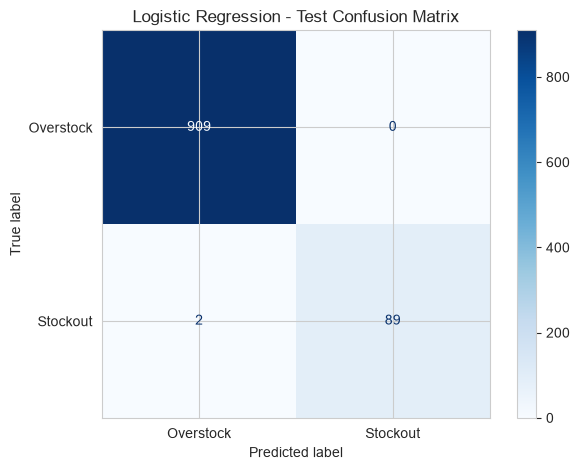

In [85]:
#Confusion Matrix

cm = confusion_matrix(
    y_test_binary,
    y_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Overstock", "Stockout"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [86]:
coefficient_table = pd.DataFrame({
    "Feature": X_train_lr.columns,
    "Coefficient": log_reg.coef_[0]})

coefficient_table["Direction"] = np.where(
    coefficient_table["Coefficient"] < 0,
    "Lower stockout odds",
    "Higher stockout odds")

coefficient_table = coefficient_table.sort_values(
    "Coefficient",
    ascending=True
).reset_index(drop=True)

display(coefficient_table.round(4))

,Feature,Coefficient,Direction
0,stock_minus_reorder,-8.4272,Lower stockout odds
1,stock_to_reorder_ratio,-6.7564,Lower stockout odds
2,days_of_cover,-0.3987,Lower stockout odds
3,item_category,-0.2319,Lower stockout odds
4,lead_time_days,-0.1402,Lower stockout odds
5,forecast_error,-0.0755,Lower stockout odds
6,season,0.0573,Higher stockout odds
7,sales_last_30_days,0.1165,Higher stockout odds
8,supplier_reliability,0.1277,Higher stockout odds
9,stock_turnover_ratio,0.2516,Higher stockout odds


In [87]:
probability_results = pd.DataFrame({
    "Actual_Status": pd.Series(y_test).reset_index(drop=True),
    "Stockout_Probability": stockout_probability,
    "Predicted_Status": np.where(
        y_test_pred == 1, "stockout", "overstock"
    )
})

probability_results["Stockout_Probability_%"] = (
    probability_results["Stockout_Probability"] * 100
).round(2)

display(probability_results.head(20))

,Actual_Status,Stockout_Probability,Predicted_Status,Stockout_Probability_%
0,0,8.068735e-03,overstock,0.81
1,0,4.146482e-02,overstock,4.15
2,0,7.782102e-07,overstock,0.00
3,1,9.999942e-01,stockout,100.00
4,0,3.109392e-06,overstock,0.00
5,0,1.349277e-06,overstock,0.00
6,0,2.812299e-13,overstock,0.00
7,0,1.449000e-18,overstock,0.00
8,0,7.561480e-05,overstock,0.01
9,0,5.046470e-01,overstock,50.46


In [88]:
print("Target classes:", log_reg.classes_)
print("\nOriginal target distribution:")
print(pd.Series(y_train).value_counts())
print("\nTarget encoding used in the notebook:")
print(df["stock_status"].value_counts())

Target classes: [0 1]

Original target distribution:
stock_status
0    3634
1     366
Name: count, dtype: int64

Target encoding used in the notebook:
stock_status
overstock    4543
stockout      457
Name: count, dtype: int64


In [89]:
from sklearn.metrics import confusion_matrix

print("Confusion matrix:")
print(confusion_matrix(y_test_binary, y_test_pred, labels=[0, 1]))
print("\nNumber of actual stockouts:", int(y_test_binary.sum()))
print("Number of correctly identified stockouts:",
      int(((y_test_binary == 1) & (y_test_pred == 1)).sum()))
print("Number of missed stockouts:",
      int(((y_test_binary == 1) & (y_test_pred == 0)).sum()))
print("Number of false stockout alerts:",
      int(((y_test_binary == 0) & (y_test_pred == 1)).sum()))

Confusion matrix:
[[909   0]
 [  2  89]]

Number of actual stockouts: 91
Number of correctly identified stockouts: 89
Number of missed stockouts: 2
Number of false stockout alerts: 0


## Deployment

In [90]:
import joblib
import os

model_bundle = {
    "model": log_reg,
    "scaler": scaler,
    "feature_names": list(X_train_lr.columns),
    "scale_cols": list(scale_cols),
    "num_cols": list(num_cols),
    "eng_cols": list(eng_cols),
    "encoding_maps": encoding_maps,
    "threshold": float(best_threshold),
    "stockout_class": 1,
    "drop_features": [
        "current_stock",
        "reorder_point",
        "avg_daily_demand"
    ]
}

joblib.dump(model_bundle, "model.pkl")

print("Model saved:", os.path.exists("model.pkl"))
print("Threshold:", model_bundle["threshold"])
print("Expected features:", model_bundle["feature_names"])


Model saved: True
Threshold: 0.8
Expected features: ['lead_time_days', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error', 'season', 'item_category', 'supplier_reliability', 'stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']


In [91]:
print("Feature engineering function:", add_inventory_features)
print("Encoding maps:", encoding_maps)
print("Numerical columns:", num_cols)
print("Scaling columns:", scale_cols)
print("Engineered columns:", eng_cols)
print("Threshold:", best_threshold)
print("Model input columns:", list(X_train_lr.columns))

Feature engineering function: <function add_inventory_features at 0x00000197AB228250>
Encoding maps: {'season': {'off-peak': 0, 'peak': 1}, 'item_category': {'non-essential': 0, 'essential': 1}, 'supplier_reliability': {'low': 0, 'high': 1}}
Numerical columns: ['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error']
Scaling columns: ['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error', 'stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']
Engineered columns: ['stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']
Threshold: 0.8
Model input columns: ['lead_time_days', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error', 'season', 'item_category', 'supplier_reliability', 'stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']


In [92]:
import os
print("Current folder:", os.getcwd())
print("model.pkl exists:", os.path.exists("model.pkl"))

Current folder: C:\Users\sindh
model.pkl exists: True


In [93]:
import os
import joblib

print("File exists:", os.path.exists("model.pkl"))

bundle = joblib.load("model.pkl")

print("Bundle keys:", list(bundle.keys()))
print("Model type:", type(bundle["model"]).__name__)
print("Number of features:", len(bundle["feature_names"]))
print("Decision threshold:", bundle["threshold"])

File exists: True
Bundle keys: ['model', 'scaler', 'feature_names', 'scale_cols', 'num_cols', 'eng_cols', 'encoding_maps', 'threshold', 'stockout_class', 'drop_features']
Model type: LogisticRegression
Number of features: 10
Decision threshold: 0.8


In [94]:
import joblib

bundle = joblib.load("model.pkl")

print("Saved keys:", list(bundle.keys()))
print("\nFeature names:")
print(bundle["feature_names"])

print("\nScale columns:")
print(bundle["scale_cols"])

print("\nNumeric columns:")
print(bundle["num_cols"])

print("\nEngineered columns:")
print(bundle["eng_cols"])

print("\nEncoding maps:")
print(bundle["encoding_maps"])

print("\nThreshold:")
print(bundle["threshold"])

Saved keys: ['model', 'scaler', 'feature_names', 'scale_cols', 'num_cols', 'eng_cols', 'encoding_maps', 'threshold', 'stockout_class', 'drop_features']

Feature names:
['lead_time_days', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error', 'season', 'item_category', 'supplier_reliability', 'stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']

Scale columns:
['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error', 'stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']

Numeric columns:
['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error']

Engineered columns:
['stock_minus_reorder', 'stock_to_reorder_ratio', 'days_of_cover']

Encoding maps:
{'season': {'off-peak': 0, 'peak': 1}, 'item_category': {'non-essential': 0, 'essential': 1}, 'supplier_reliability': {'low': 0, 'high': 1}}

Threshold:
0

In [95]:
%run predict.py

Exception: File `'predict.py'` not found.

In [ ]:
sample_inventory = {
    "current_stock": 300,
    "avg_daily_demand": 50,
    "lead_time_days": 7,
    "reorder_point": 350,
    "sales_last_30_days": 1450,
    "stock_turnover_ratio": 4.0,
    "forecast_error": -0.5,
    "season": "peak",
    "item_category": "essential",
    "supplier_reliability": "high",
}

print(predict_stock_risk(sample_inventory))

In [ ]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

In [ ]:
import joblib

bundle = joblib.load("model.pkl")

print("Model features:", bundle["model"].n_features_in_)
print("Saved feature count:", len(bundle["feature_names"]))
print("Scaler features:", bundle["scaler"].n_features_in_)
print("Saved scale-column count:", len(bundle["scale_cols"]))

assert bundle["model"].n_features_in_ == len(bundle["feature_names"])
assert bundle["scaler"].n_features_in_ == len(bundle["scale_cols"])

print("Feature counts match.")

In [ ]:
from pathlib import Path
import zipfile

# Change this to the folder containing your project files
project_folder = Path.cwd()

# Update this if your notebook has a different filename
notebook_name = "Group6_Stock_Risk_Project (3).ipynb"

required_files = [
    "stock_risk_prediction_dataset (1).xlsx",
    notebook_name,
    "model.pkl",
    "predict.py",
]

missing = [name for name in required_files
           if not (project_folder / name).exists()]

if missing:
    print("These files are missing:", missing)
    print("Keep the notebook, model.pkl, and predict.py in the same folder.")
else:
    readme = """GROUP 6 — STOCK RISK PREDICTION

Purpose:
Predict whether inventory is at risk of stockout or overstock.

Model:
Logistic Regression with preprocessing and a saved decision threshold.

Files:
- Project notebook: data analysis, preprocessing, model training and evaluation
- model.pkl: trained model and preprocessing configuration
- predict.py: reusable prediction pipeline

Requirements:
Python, pandas, scikit-learn, joblib

Run:
1. Install dependencies if needed:
   pip install pandas scikit-learn joblib
2. Place model.pkl and predict.py in the same folder.
3. Run:
   python predict.py

Note:
Use the same feature definitions and preprocessing as the training notebook.
"""

    zip_path = project_folder / "Group6_Stock_Risk_Project.zip"

    with zipfile.ZipFile(zip_path, "w",
                         compression=zipfile.ZIP_DEFLATED) as z:
        for name in required_files:
            z.write(project_folder / name, arcname=name)
        z.writestr("README.txt", readme)

    print("ZIP created:", zip_path.resolve())
    print("Included:", required_files + ["README.txt"])

In [ ]:
import sys
import sklearn
import joblib

print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)
print("Joblib version:", joblib.__version__)

In [ ]:
bundle = joblib.load("model.pkl")
model = bundle["model"]

print("Model type:", type(model))
print("Model parameters:", model.get_params())
print("Has multi_class attribute:", hasattr(model, "multi_class"))
print("Model classes:", model.classes_)

In [ ]:
print("X_train_lr:", X_train_lr.shape)
print("y_train:", y_train.shape)
print("X_test_lr:", X_test_lr.shape)
print("y_test:", y_test.shape)

In [ ]:
pip freeze > requirements.txt

# MEMBER 3 — CSV BATCH PREDICTION

This section adds CSV batch prediction to the **same notebook**. Upload a CSV containing multiple inventory records, validate required columns, predict Stockout/Overstock for every row, review the results, and download the output CSV.

**Required CSV columns:** `current_stock`, `avg_daily_demand`, `lead_time_days`, `reorder_point`, `sales_last_30_days`, `stock_turnover_ratio`, `forecast_error`, `season`, `item_category`, `supplier_reliability`.

**Note:** This notebook interface uses Jupyter upload/download widgets. The existing Streamlit dashboard remains a separate app; this section keeps the batch workflow inside this notebook.

In [ ]:
from pathlib import Path
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, FileLink, clear_output

# Import the same saved-model prediction function used by the dashboard.
from predict import predict_stock_risk, REQUIRED_INPUTS

print("Required CSV columns:")
print(REQUIRED_INPUTS)
print("Number of required columns:", len(REQUIRED_INPUTS))

### Upload your inventory CSV
Choose a CSV file that contains one row per product. The file must include all 10 required input columns listed above.

In [ ]:
# Create the upload, prediction, and output areas.
csv_uploader = widgets.FileUpload(accept=".csv", multiple=False, description="Upload CSV")
run_batch_button = widgets.Button(description="Run Batch Prediction", button_style="primary", icon="play")
batch_output = widgets.Output()
display(csv_uploader, run_batch_button, batch_output)

def _uploaded_csv_bytes(upload_widget):
    """Read uploaded bytes across common ipywidgets 7/8 formats."""
    value = upload_widget.value
    if not value:
        raise ValueError("Please upload a CSV file first.")
    if isinstance(value, dict):  # ipywidgets 8
        item = next(iter(value.values()))
        content = item["content"]
        filename = item.get("name", "inventory.csv")
    else:  # ipywidgets 7
        item = value[0]
        content = item["content"]
        filename = item.get("name", "inventory.csv")
    return filename, bytes(content)

def _run_batch_prediction(_button):
    with batch_output:
        clear_output()
        try:
            filename, content = _uploaded_csv_bytes(csv_uploader)
            if not filename.lower().endswith(".csv"):
                raise ValueError("The uploaded file must be a .csv file.")
            from io import BytesIO
            input_df = pd.read_csv(BytesIO(content))
            input_df.columns = input_df.columns.astype(str).str.strip()
            missing_columns = [c for c in REQUIRED_INPUTS if c not in input_df.columns]
            if missing_columns:
                raise ValueError("Missing required columns: " + ", ".join(missing_columns))
            if input_df.empty:
                raise ValueError("The uploaded CSV has no data rows.")

            result_rows = []
            for row_number, (_, row) in enumerate(input_df.iterrows(), start=1):
                record = {column: row[column] for column in REQUIRED_INPUTS}
                try:
                    prediction = predict_stock_risk(record)
                    result_rows.append({
                        "row_number": row_number,
                        "predicted_status": prediction["status"],
                        "stockout_probability_percent": prediction["stockout_probability_percent"],
                        "decision_threshold": prediction["threshold"],
                        "error": ""
                    })
                except (ValueError, TypeError, KeyError) as error:
                    result_rows.append({
                        "row_number": row_number,
                        "predicted_status": "Invalid input",
                        "stockout_probability_percent": None,
                        "decision_threshold": None,
                        "error": str(error)
                    })

            results_df = pd.concat([input_df.reset_index(drop=True), pd.DataFrame(result_rows)], axis=1)
            output_path = Path.cwd() / "batch_prediction_results.csv"
            results_df.to_csv(output_path, index=False)
            valid_count = int((results_df["predicted_status"] != "Invalid input").sum())
            stockout_count = int((results_df["predicted_status"] == "Stockout").sum())
            overstock_count = int((results_df["predicted_status"] == "Overstock").sum())
            invalid_count = int((results_df["predicted_status"] == "Invalid input").sum())
            print(f"Uploaded file: {filename}")
            print(f"Total products: {len(results_df)} | Predicted: {valid_count} | Invalid rows: {invalid_count}")
            print(f"Stockout predictions: {stockout_count} | Overstock predictions: {overstock_count}")
            display(results_df.head(20))
            print("Download the full results:")
            display(FileLink(str(output_path)))
        except Exception as error:
            print("Batch prediction could not be completed:", error)

run_batch_button.on_click(_run_batch_prediction)

### How to demonstrate this feature
1. Prepare a CSV with the 10 required columns and multiple product rows.
2. Run the upload-widget cell and upload the CSV.
3. Click **Run Batch Prediction**.
4. Review predicted status, stockout probability, threshold, and row-level validation errors.
5. Click the `batch_prediction_results.csv` link to download all results.

If `ipywidgets` is missing, install it in the same Python environment as Jupyter with `%pip install ipywidgets`, then restart the kernel and rerun this section. The notebook also needs `predict.py` and the matching `model.pkl` in its working folder.

# MEMBER 4 — RESULTS AND VISUALIZATIONS


This section presents the results and visualization part of the Stock Risk Prediction project. It reports predicted stockout/overstock counts, plots the predicted risk distribution, and calculates evaluation metrics plus a confusion matrix **only when actual labelled outcomes are available**.

**Files needed in the notebook's working folder:** `model.pkl`, `predict.py` and `sample_inventory.csv` (or point `sample_path` below to your own inventory CSV). If you are using Google Colab, upload those files or mount the folder containing them.

This section is self-contained: it re-imports what it needs, so it can be run on its own after the earlier sections.

In [ ]:
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
print("Working folder:", PROJECT_DIR)
print("Files found:", [p.name for p in PROJECT_DIR.iterdir() if p.is_file()][:20])


### 1. Load the sample inventory data and prediction function

The CSV must contain the 10 inventory input columns used by the trained model. The sample CSV is used for a quick demonstration; upload or point to your full inventory dataset for real project results.


In [ ]:
REQUIRED_COLUMNS = [
    "current_stock", "avg_daily_demand", "lead_time_days", "reorder_point",
    "sales_last_30_days", "stock_turnover_ratio", "forecast_error",
    "season", "item_category", "supplier_reliability"
]

sample_path = PROJECT_DIR / "sample_inventory.csv"
if not sample_path.exists():
    raise FileNotFoundError(
        "sample_inventory.csv was not found. Put it beside this notebook, "
        "or change sample_path to the location of your inventory CSV."
    )

inventory_df = pd.read_csv(sample_path)
inventory_df.columns = [str(c).strip() for c in inventory_df.columns]
missing = [c for c in REQUIRED_COLUMNS if c not in inventory_df.columns]
if missing:
    raise ValueError(f"CSV is missing required columns: {missing}")

print(f"Loaded {len(inventory_df)} inventory records.")
display(inventory_df.head())


In [ ]:
# Use the project's shared prediction pipeline and saved model bundle.
from predict import predict_stock_risk

prediction_rows = []
for _, row in inventory_df.iterrows():
    record = {column: row[column] for column in REQUIRED_COLUMNS}
    try:
        result = predict_stock_risk(record)
        prediction_rows.append({
            **row.to_dict(),
            "predicted_status": result["status"],
            "stockout_probability": result["stockout_probability"],
            "stockout_probability_percent": result["stockout_probability_percent"],
            "decision_threshold": result["threshold"],
            "row_status": "Success",
            "error_message": ""
        })
    except Exception as exc:
        prediction_rows.append({
            **row.to_dict(),
            "predicted_status": "Invalid input",
            "stockout_probability": np.nan,
            "stockout_probability_percent": np.nan,
            "decision_threshold": np.nan,
            "row_status": "Failed",
            "error_message": str(exc)
        })

results_df = pd.DataFrame(prediction_rows)
display(results_df)


### 2. Stockout and overstock counts

These counts summarize the model's predictions for the loaded records. They are **predicted** outcomes, not confirmed real-world stock events.


In [ ]:
successful = results_df[results_df["row_status"] == "Success"].copy()
pred_counts = successful["predicted_status"].value_counts().reindex(
    ["Stockout", "Overstock"], fill_value=0
)

print("Total records:", len(results_df))
print("Successful predictions:", len(successful))
print("Failed / invalid rows:", int((results_df["row_status"] == "Failed").sum()))
print("Predicted stockouts:", int(pred_counts["Stockout"]))
print("Predicted overstock:", int(pred_counts["Overstock"]))

fig, ax = plt.subplots(figsize=(7, 4))
pred_counts.plot(kind="bar", ax=ax)
ax.set_title("Predicted Stockout and Overstock Counts")
ax.set_xlabel("Predicted inventory status")
ax.set_ylabel("Number of products")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 3. Predicted risk distribution

The histogram shows model-estimated stockout probabilities. A higher probability indicates that the model considers the item more likely to experience a stockout. It is not a measure of financial loss or risk severity.


In [ ]:
probabilities = successful["stockout_probability"].dropna()

if probabilities.empty:
    print("No valid stockout probabilities are available to plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(probabilities, bins=10, edgecolor="black")
    ax.set_title("Distribution of Predicted Stockout Probabilities")
    ax.set_xlabel("Predicted stockout probability")
    ax.set_ylabel("Number of products")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(probabilities * 100, bins=10, edgecolor="black")
    ax.set_title("Stockout Risk Distribution (%)")
    ax.set_xlabel("Predicted stockout probability (%)")
    ax.set_ylabel("Number of products")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


### 4. Evaluation metrics and confusion matrix

For valid evaluation, the input data must include an actual target column named `stock_status`, containing labels such as `stockout` and `overstock`. The sample input CSV does not include actual outcomes, so accuracy, precision, recall, F1-score, and a confusion matrix cannot be calculated from it. The notebook will not invent evaluation results.

If labelled data is supplied, the metrics below compare model predictions against actual labels.


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

if "stock_status" not in inventory_df.columns:
    print(
        "Evaluation skipped: this dataset has no 'stock_status' actual-label column. "
        "Use a labelled test dataset to calculate genuine evaluation metrics."
    )
else:
    evaluation_df = results_df[
        (results_df["row_status"] == "Success") &
        (results_df["predicted_status"].isin(["Stockout", "Overstock"]))
    ].copy()

    actual = evaluation_df["stock_status"].astype(str).str.strip().str.lower()
    valid_label = actual.isin(["stockout", "overstock"])
    evaluation_df = evaluation_df.loc[valid_label].copy()
    actual = actual.loc[valid_label].map({"overstock": 0, "stockout": 1})
    predicted = evaluation_df["predicted_status"].map({"Overstock": 0, "Stockout": 1})

    if evaluation_df.empty:
        print("Evaluation skipped: no usable stock_status labels were found.")
    else:
        metrics_df = pd.DataFrame({
            "Metric": ["Accuracy", "Stockout precision", "Stockout recall", "Stockout F1-score"],
            "Score": [
                accuracy_score(actual, predicted),
                precision_score(actual, predicted, zero_division=0),
                recall_score(actual, predicted, zero_division=0),
                f1_score(actual, predicted, zero_division=0)
            ]
        })
        display(metrics_df.style.format({"Score": "{:.3f}"}))

        print(classification_report(
            actual, predicted, labels=[0, 1],
            target_names=["Overstock", "Stockout"], zero_division=0
        ))

        cm = confusion_matrix(actual, predicted, labels=[0, 1])
        display(pd.DataFrame(
            cm,
            index=["Actual Overstock", "Actual Stockout"],
            columns=["Predicted Overstock", "Predicted Stockout"]
        ))

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Overstock", "Stockout"]
        )
        disp.plot(values_format="d")
        plt.title("Confusion Matrix — Actual vs Predicted")
        plt.tight_layout()
        plt.show()

        true_stockouts = int((actual == 1).sum())
        correctly_detected = int(((actual == 1) & (predicted == 1)).sum())
        missed_stockouts = int(((actual == 1) & (predicted == 0)).sum())
        false_alerts = int(((actual == 0) & (predicted == 1)).sum())
        print("Actual stockouts:", true_stockouts)
        print("Correctly identified stockouts:", correctly_detected)
        print("Missed stockouts (false negatives):", missed_stockouts)
        print("False stockout alerts (false positives):", false_alerts)


### 5. Business meaning of model errors

- **Missed stockout (false negative):** the model predicts overstock, but the item actually stocks out. This can contribute to lost sales, customer dissatisfaction, and emergency replenishment.
- **False stockout alert (false positive):** the model predicts stockout, but the actual outcome is overstock. This may lead to unnecessary replenishment, excess holding costs, or tied-up working capital.
- **Precision:** among items flagged as stockout risk, the fraction that really were stockouts.
- **Recall:** among actual stockouts, the fraction detected by the model.
- **F1-score:** balances precision and recall.

For inventory planning, the right decision threshold depends on the relative cost of a missed stockout versus an unnecessary alert. Use a held-out labelled test set when reporting final model performance.


### 6. Export the prediction results

Save the results so they can be reviewed or used in the project report.


In [ ]:
output_path = PROJECT_DIR / "member4_prediction_results.csv"
results_df.to_csv(output_path, index=False)
print(f"Prediction results saved to: {output_path.resolve()}")


# Member 5 -GitHub Integration and Deployment

This section presents the GitHub integration and deployment part of the Stock Risk prediction project. It explains how to save the trained Machine learning model, prepare the required application files, upload the Stremlit Community Cloud.

Files needed for deployment
'app.py',
'requirements.txt',
'stock_risk_model.pkl',

This section helps make Stock Risk Prediction application accessible through web browser.

In [145]:
#Import the lib
import os
import joblib
import streamlit as st

In [127]:

#Save the trained model to a file named "stock_prediction_model.pkl" using joblib
joblib.dump(model,
            "stock_prediction_model.pkl")

#print the confirmation message indicating the model was saved successfully.
print("Model saved successfully!")
#Print the datatype/class of the saved model to verify its type.
print("Model type:", type(model))

Model saved successfully!
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [124]:
#Define the Filename of the saved Machine learning model

model_path = "stock_prediction_model.pkl"

#Check whether the model file is avilabel
if os.path.exists(model_path):
    print("Stock prediction model is available.")

else:
    print("Stock prediction model is not available.")
    print("Please train the model and save it before deployment.")

Stock prediction model is available.


In [126]:
#Check whether the model file exists

model_file = "stock_prediction_model.pkl"

if os.path.exists(model_file):

    print("Model file verified successfully.")
    print("Filename:", model_file)

    #Display the file size in KB
    file_size = os.path.getsize(model_file) / 1024

    print(f"File size: {file_size:.2f} KB")


else:
    print("Model file not found.")
    


Model file verified successfully.
Filename: stock_prediction_model.pkl
File size: 1302.79 KB


In [147]:
%%writefile app.py
#Set up the main title of the web application
st.title("Stock Risk Prediction")

st.write("Welcome to the Stock Risk Prediction App!")

model = joblib.load("stock_prediction_model.pkl")

st.success("Model loaded successfully!")

Writing app.py


In [133]:
#Display the Model's Required Features
#Check whether the model contains features names

if hasattr(model, "feature_names_in_"):

    #Display the features used during training
    print("Features used during model training:")

    for features in model.feature_names_in_:
        print("-", features)

    else:
        print("Features names are not avilable in the model.")
        print("Check the original model training code.")

Features used during model training:
- current_stock
- avg_daily_demand
- lead_time_days
- reorder_point
- sales_last_30_days
- stock_turnover_ratio
- forecast_error
- season_peak
- item_category_non-essential
- supplier_reliability_low
Features names are not avilable in the model.
Check the original model training code.


#### Check the Files Required For Deployment

In [137]:
#List the files required for streamlit deployment

required_files = [
    "app.py",
    "requirements.txt",
    "stock_prediction_model.pkl"
]


print("Deployment File Check")


for file in required_files:
    if os.path.exists(file):
        print(file, "-Available")

    else:
        print(file, "- Not found")

Deployment File Check
app.py -Available
requirements.txt -Available
stock_prediction_model.pkl -Available


##### Final Deployment Readiness Check

In [144]:
#Check whether all required deployment files are present

required_files = [
    "app.py",
    "requirements.txt",
    "stock_prediction_model.pkl"
]


missing_files = [
    file for file in required_files
    if not os.path.exists(file)
]


#Dispaly the final status

if len(missing_files) == 0:
    print("All required deployment files are available.")
    print("You can proceed to GitHub upload.")
else:
    print("Deployment is not ready.")
    print("Missing files:")

    for file in missing_files:
        print("-", file)

All required deployment files are available.
You can proceed to GitHub upload.
